# Proposed method (PMRT, EEG + chin EMG) vs published methods, re-implemented on the same protocol
All methods: same 103 subjects, same 5 subject-wise folds (`folds_5.json`), same labels and the same metric code as PMRT.

| Method | Paper | Signals | Approach |
|---|---|---|---|
| Sharma 2021 | Electronics 10:1531 (CAP, sleep-disorder types) | EEG | sub-bands + Hjorth, ensemble boosted trees |
| Sharma 2022 | Comput Biol Med 143:105224 (CAP, same 6 classes as ours) | EMG | wavelet sub-bands + Hjorth, ensemble bagged trees |
| Cheng 2023 | Sensors 23:3468 (CAP, sleep stage + disorder, deep learning) | EEG + EMG | STFT spectrogram, one VGG-style CNN per modality, fusion NN (2 x 128) |
| EEGNet | Lawhern et al. 2018, J Neural Eng 15:056013 (standard compact EEG CNN) | EEG + EMG (2 channels) | temporal conv, depthwise spatial conv, separable conv |
| AttnSleep | Eldele et al. 2021, IEEE TNSRE 29:809 (sleep staging) | EEG | multi-resolution CNN + adaptive feature recalibration + multi-head attention |
| Band power + RF | classic baseline | EEG + EMG | Welch power in 7 bands (absolute + relative), Random Forest |

**Adaptations (state in the thesis):** 125 Hz and 5-s windows for every method; Sharma 2021's triplet half-band filter bank replaced by a biorthogonal wavelet (bior2.2, level 5); Sharma 2022 used EOG + EMG, here chin EMG only; Cheng 2023 used 10-s windows at 512 Hz, colour-mapped spectrogram images, VGG16 and ECG as an extra modality: here a single-channel log spectrogram, a compact 10-layer VGG and no ECG (our HR / RMSSD labels come from ECG). Deep EEG baselines: original single-channel inputs kept (EEG; EEGNet uses both signals as channels), filter sizes scaled to 5-s windows at 125 Hz, Adam (lr 1e-3), same multi-task heads and loss as the other deep baseline. Every method also predicts HR and ln(RMSSD) so that the stress index can be compared. Fixed settings, no tuning on test data.

Sections: 1 data · 2-3 Sharma 2021 / 2022 · 4 random vs subject-wise split · 5-6 Cheng 2023 · 7-9 comparison table, paired tests, figures.

**Runs on Colab or Kaggle (detected automatically).** `ONLY_NEW_METHODS = True` (settings cell): Sharma 2021/2022, the leakage check and Cheng 2023 are skipped because they were already trained; only band power + RF, EEGNet and AttnSleep are trained. Set it to `False` to train everything from scratch.
- **Colab:** Runtime -> T4 GPU -> Run all. After a disconnect run all again: finished folds and trained CNNs are skipped.
- **Kaggle:** Settings: Accelerator = GPU T4, Internet = On. `Save Version` -> **Save & Run All (Commit)** (runs in the background, up to 12 h; no new fold is started after 10.5 h). The data are downloaded from the shared Drive zip (same as `pmrt_ablation_kaggle`). Kaggle trains the baselines only; afterwards download the output, put `baselines/` and `tables/baselines/` into `sleep_project` on Drive and run this notebook once in Colab (CPU is enough) to make the comparison table and figures. If a Kaggle run stops at the time limit: Add Input -> Your Work -> this notebook's output, then commit again (finished folds are skipped).
Visual comparison (figB08-B27): heat map of all metrics, radar chart, confusion matrices of every method, per-class F1 / recall, ROC curves, per-subject scatter and violin plots, per-fold stability, bootstrap confidence intervals, example hypnogram, fusion ablation, and one figure for every metric where the proposed method beats all three published methods (B22-B27).

Outputs (own sub-folders, so re-running `pmrt_final_results` never deletes them): `tables/baselines/` (tableB01-B03, baselines_comparison.xlsx), `figures/{png,pdf,svg}/baselines/` (figB01-B07).

**Labels:** *Proposed (ours)* = the final model of the thesis (PMRT, EEG + chin EMG fusion, run `pmrt_mt3_cv5`). The main comparison (tableB01, figB01-B20, B22-B27) contains the published methods and the proposed method only; the single-branch ablations of the proposed method are reported separately (tableB06, figB21).

In [1]:
# Environment: Google Colab (data on Google Drive) or Kaggle (data downloaded from the shared Drive zip)
import os, sys, glob, shutil, subprocess, zipfile, time
from pathlib import Path
KAGGLE = os.path.exists("/kaggle/working")
FILE_ID = "11VPVORnZ951jWSle1wMWC0DAuLz5aFC-"
T_START, TIME_LIMIT_H = time.time(), 10.5
if KAGGLE:
    ROOT = Path("/kaggle/working")
    hits = sorted(glob.glob("/kaggle/input/**/x.npy", recursive=True))
    if not hits:
        tmp = Path("/tmp/capdata")
        if not list(tmp.rglob("x.npy")):
            try:
                import gdown
            except ImportError:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True); import gdown
            tmp.mkdir(parents=True, exist_ok=True)
            gdown.download(id=FILE_ID, output="/tmp/cap.zip", quiet=False)
            zipfile.ZipFile("/tmp/cap.zip").extractall(tmp); os.remove("/tmp/cap.zip")
        hits = sorted(str(p) for p in tmp.rglob("x.npy"))
    assert hits, "x.npy not found in the zip / Kaggle input"
    DATA = Path(hits[0]).parent
    folds = sorted(glob.glob(str(DATA / "folds_5.json")) + glob.glob("/tmp/capdata/**/folds_5.json", recursive=True)
                   + glob.glob("/kaggle/input/**/folds_5.json", recursive=True))
    assert folds, "folds_5.json not found"
    FOLDS_FILE = Path(folds[0])
    for prev in glob.glob("/kaggle/input/**/baselines", recursive=True):
        shutil.copytree(prev, ROOT / "baselines", dirs_exist_ok=True)
        print("previous Kaggle output found and copied:", prev)
else:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    ROOT = Path("/content/drive/MyDrive/sleep_project")
    DATA, FOLDS_FILE = ROOT / "cap_dataset_cache", ROOT / "folds_5.json"
print("platform:", "Kaggle" if KAGGLE else "Colab", "| data:", DATA, "| folds:", FOLDS_FILE, "| outputs:", ROOT)
print("files in data folder:", sorted(os.listdir(DATA)))

Mounted at /content/drive
platform: Colab | data: /content/drive/MyDrive/sleep_project/cap_dataset_cache | folds: /content/drive/MyDrive/sleep_project/folds_5.json | outputs: /content/drive/MyDrive/sleep_project
files in data folder: ['index.csv', 'x.npy']


In [2]:
# Shared helpers, identical to pmrt_mt3.py (labels, data loading, subject-wise folds, subject-balanced batches)
import math, types, numpy as np, pandas as pd, torch
DISORDERS = ["Healthy", "NFLE", "RBD", "PLM", "Insomnia", "Narcolepsy"]
STAGES = ["N1", "N2", "N3", "REM"]
IGNORE = -100

def load_data(cache_dir):
    X = np.load(Path(cache_dir) / "x.npy")
    idx = pd.read_csv(Path(cache_dir) / "index.csv")
    idx["dis"] = idx.group.map({g: i for i, g in enumerate(DISORDERS)}).fillna(IGNORE).astype(int)
    idx["stg"] = idx.stage.map({s: i for i, s in enumerate(STAGES)}).astype(int)
    return X, idx

def fold_rows(idx, fold, k_test, k=5):
    f = idx.record.map(fold).to_numpy()
    k_val = (k_test + 1) % k
    return {"train": np.where((f != k_test) & (f != k_val))[0],
            "val": np.where(f == k_val)[0], "test": np.where(f == k_test)[0]}

class SubjectBalancedBatches:
    def __init__(self, X, Y, rows, rec, batch, device, per_subject=1500, shuffle=True):
        self.X, self.Y, self.b, self.dev, self.k, self.sh = X, Y, batch, device, per_subject, shuffle
        self.groups = [rows[rec[rows] == r] for r in np.unique(rec[rows])] if shuffle else None
        self.rows = rows
    def _epoch_rows(self):
        if not self.sh: return self.rows
        pick = [g if len(g) <= self.k else np.random.choice(g, self.k, replace=False) for g in self.groups]
        return np.random.permutation(np.concatenate(pick))
    def __len__(self):
        n = sum(min(len(g), self.k) for g in self.groups) if self.sh else len(self.rows)
        return math.ceil(n / self.b)
    def __iter__(self):
        r = self._epoch_rows()
        for i in range(0, len(r), self.b):
            j = np.sort(r[i:i + self.b])
            x = torch.from_numpy(np.asarray(self.X[j], dtype=np.float32)).to(self.dev, non_blocking=True)
            y = {k: torch.from_numpy(v[j]).to(self.dev, non_blocking=True) for k, v in self.Y.items()}
            yield x, y, j

M = types.SimpleNamespace(DISORDERS=DISORDERS, STAGES=STAGES, IGNORE=IGNORE, load_data=load_data, fold_rows=fold_rows,
                          SubjectBalancedBatches=SubjectBalancedBatches)

In [3]:
# Settings, GPU, data and the same subject-wise folds as PMRT
import sys, json, time, importlib, warnings, numpy as np, pandas as pd, pywt, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier, GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, accuracy_score, cohen_kappa_score, f1_score
from scipy.stats import wilcoxon
warnings.filterwarnings("ignore")

OUT = ROOT / "baselines"
N_FOLDS, SEED, PER_SUBJECT = 5, 42, 1500
WAVELET, LEVEL, N_LEARNERS = "bior2.2", 5, 30
RUN_NAME, BATCH, EPOCHS, PATIENCE = "cheng2023_mmldms", 256, 30, 5
LR, MOMENTUM, WD, N_FFT, HOP = 0.01, 0.9, 5e-4, 128, 8
MODALITIES = {"eeg": 0, "emg": 1}
ONLY_NEW_METHODS = True

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "- WARNING: no GPU (Cheng et al. part will be very slow)")
TABB = ROOT / "tables" / "baselines"
for p in [OUT / "runs", TABB] + [ROOT / "figures" / e / "baselines" for e in ("png", "pdf", "svg")]:
    p.mkdir(parents=True, exist_ok=True)
X, idx = M.load_data(str(DATA))
FOLD = json.loads(FOLDS_FILE.read_text())
REC = idx.record.to_numpy()
DIS, STG = M.DISORDERS, M.STAGES
y_hr, y_lrm = idx.hr.to_numpy(np.float32), np.log(np.maximum(idx.rmssd.to_numpy(np.float32), 1.0))
y_dis, y_stg = idx.dis.to_numpy(), idx.stg.to_numpy()
LRM = y_lrm
RUN = OUT / "runs" / RUN_NAME; RUN.mkdir(parents=True, exist_ok=True)
print("windows:", X.shape, "| subjects:", idx.record.nunique())

device: cpu - WARNING: no GPU (Cheng et al. part will be very slow)
windows: (483170, 2, 625) | subjects: 103


In [4]:
# Wavelet sub-bands + Hjorth parameters of every 5-s window (EEG and chin EMG), computed once and cached
def hjorth(c):
    d1 = np.diff(c, axis=1); d2 = np.diff(d1, axis=1)
    v0, v1, v2 = c.var(1), d1.var(1), d2.var(1)
    mob = np.sqrt(v1 / (v0 + 1e-12))
    comp = np.sqrt(v2 / (v1 + 1e-12)) / (mob + 1e-12)
    return np.stack([np.log(v0 + 1e-12), mob, comp], 1)

def wavelet_hjorth(sig):
    return np.concatenate([hjorth(c) for c in pywt.wavedec(sig, WAVELET, level=LEVEL, axis=1)], 1).astype(np.float32)

feat_file = OUT / "features_wavelet_hjorth.npz"
if feat_file.exists():
    FEAT = dict(np.load(feat_file))
else:
    t0, chunk, parts = time.time(), 20000, {"eeg": [], "emg": []}
    for a in range(0, len(X), chunk):
        x = np.asarray(X[a:a + chunk], dtype=np.float32)
        parts["eeg"].append(wavelet_hjorth(x[:, 0])); parts["emg"].append(wavelet_hjorth(x[:, 1]))
        print(f"  {min(a + chunk, len(X)):,}/{len(X):,} windows ({time.time() - t0:.0f} s)", flush=True)
    FEAT = {k: np.concatenate(v) for k, v in parts.items()}
    np.savez(feat_file, **FEAT)
print({k: v.shape for k, v in FEAT.items()}, "|", LEVEL + 1, "sub-bands x 3 Hjorth parameters per signal")

{'eeg': (483170, 18), 'emg': (483170, 18)} | 6 sub-bands x 3 Hjorth parameters per signal


In [5]:
# The two published methods as described in their papers (same 5 subject-wise folds as PMRT, fixed settings, no tuning)
def boosted_clf(seed): return AdaBoostClassifier(DecisionTreeClassifier(max_leaf_nodes=21), n_estimators=N_LEARNERS, learning_rate=0.1, random_state=seed)
def boosted_reg(seed): return GradientBoostingRegressor(n_estimators=N_LEARNERS, learning_rate=0.1, max_leaf_nodes=21, random_state=seed)
def bagged_clf(seed): return RandomForestClassifier(n_estimators=N_LEARNERS, max_features=None, n_jobs=-1, random_state=seed)
def bagged_reg(seed): return RandomForestRegressor(n_estimators=N_LEARNERS, max_features=None, min_samples_leaf=5, n_jobs=-1, random_state=seed)

METHODS = {"sharma2021_eeg": {"features": FEAT["eeg"], "clf": boosted_clf, "reg": boosted_reg,
                              "paper": "Sharma et al. 2021, Electronics 10:1531 - EEG, sub-bands + Hjorth, ensemble boosted trees"},
           "sharma2022_emg": {"features": FEAT["emg"], "clf": bagged_clf, "reg": bagged_reg,
                              "paper": "Sharma et al. 2022, Comput Biol Med 143:105224 - EMG, wavelet sub-bands + Hjorth, ensemble bagged trees"}}

def balanced_rows(rows, rng):
    out = []
    for r in np.unique(REC[rows]):
        g = rows[REC[rows] == r]
        out.append(g if len(g) <= PER_SUBJECT else rng.choice(g, PER_SUBJECT, replace=False))
    return np.sort(np.concatenate(out))

def proba(model, Z, n):
    p, out = model.predict_proba(Z), np.zeros((len(Z), n), np.float32)
    out[:, model.classes_] = p
    return out

if ONLY_NEW_METHODS:
    print("Sharma 2021 / 2022: already trained (ONLY_NEW_METHODS = True) - skipped")
else:
    for tag, cfg in METHODS.items():
        run = OUT / "runs" / tag; run.mkdir(parents=True, exist_ok=True); Z = cfg["features"]
        print(cfg["paper"])
        for k in range(N_FOLDS):
            f = run / f"fold{k}.csv"
            if f.exists():
                print(f"  fold {k}: done - skipped"); continue
            if time.time() - T_START > TIME_LIMIT_H * 3600:
                print("  time limit reached - run again to continue"); break
            t0 = time.time(); rng = np.random.default_rng(SEED + k)
            rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
            tr = balanced_rows(np.concatenate([rows["train"], rows["val"]]), rng); te = np.sort(rows["test"])
            out = idx.iloc[te][["record", "group", "stage", "clipped", "dis", "stg", "hr", "rmssd"]].reset_index(drop=True)
            out["fold"] = k
            out["hr_pred"] = cfg["reg"](SEED + k).fit(Z[tr], y_hr[tr]).predict(Z[te])
            out["rmssd_pred"] = np.exp(cfg["reg"](SEED + k).fit(Z[tr], y_lrm[tr]).predict(Z[te]))
            td = tr[y_dis[tr] != M.IGNORE]
            pdis = proba(cfg["clf"](SEED + k).fit(Z[td], y_dis[td]), Z[te], len(DIS))
            pstg = proba(cfg["clf"](SEED + k).fit(Z[tr], y_stg[tr]), Z[te], len(STG))
            for i, c in enumerate(DIS): out[f"p_{c}"] = pdis[:, i]
            for i, s in enumerate(STG): out[f"p_{s}"] = pstg[:, i]
            out.to_csv(f, index=False)
            print(f"  fold {k}: {len(tr):,} training windows -> saved ({time.time() - t0:.0f} s)", flush=True)
    print("all folds finished")

Sharma 2021 / 2022: already trained (ONLY_NEW_METHODS = True) - skipped


In [6]:
# Why published CAP accuracies are so high: the same methods with a random window split vs a subject-wise split (disorder, 6 classes)
if ONLY_NEW_METHODS:
    print("leakage check: already done (ONLY_NEW_METHODS = True) - skipped")
else:
    LEAK_FILE = TABB / "tableB03_leakage_random_vs_subject_split.csv"
    if LEAK_FILE.exists():
        leak = pd.read_csv(LEAK_FILE); print("already computed - loaded")
    else:
        rng = np.random.default_rng(SEED)
        pool = balanced_rows(np.arange(len(idx)), rng); pool = pool[y_dis[pool] != M.IGNORE]
        rows = []
        for tag, cfg in ((t, c) for t, c in METHODS.items() if t.startswith("sharma")):
            Z = cfg["features"]; yt, pr = [], []
            for k, (a, b) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(pool, y_dis[pool])):
                clf = cfg["clf"](SEED + k).fit(Z[pool[a]], y_dis[pool[a]]); yt.append(y_dis[pool[b]]); pr.append(clf.predict(Z[pool[b]]))
            yt, pr = np.concatenate(yt), np.concatenate(pr)
            rows.append({"method": cfg["paper"], "protocol": "random window split (as in the papers)",
                         "window accuracy": accuracy_score(yt, pr), "window balanced acc": balanced_accuracy_score(yt, pr)})
            d = pd.concat([pd.read_csv(OUT / "runs" / tag / f"fold{k}.csv") for k in range(N_FOLDS)]); d = d[d.dis != M.IGNORE]
            pp = d[[f"p_{c}" for c in DIS]].to_numpy().argmax(1)
            rows.append({"method": cfg["paper"], "protocol": "subject-wise split (test subjects never seen)",
                         "window accuracy": accuracy_score(d.dis, pp), "window balanced acc": balanced_accuracy_score(d.dis, pp)})
        leak = pd.DataFrame(rows); leak.to_csv(LEAK_FILE, index=False)
    print(leak.round(3).to_string(index=False))

leakage check: already done (ONLY_NEW_METHODS = True) - skipped


In [7]:
# Cheng et al. 2023 (MML-DMS): STFT spectrogram -> one VGG-style CNN per modality -> fusion NN with two hidden layers of 128
class Spectrogram(nn.Module):
    def __init__(self):
        super().__init__(); self.register_buffer("w", torch.hann_window(N_FFT))
    def forward(self, x):
        s = torch.log1p(torch.stft(x, N_FFT, HOP, window=self.w, return_complex=True).abs())
        s = (s - s.mean((1, 2), keepdim=True)) / (s.std((1, 2), keepdim=True) + 1e-6)
        return s[:, None]

def vgg_block(c_in, c_out, n):
    layers = []
    for _ in range(n):
        layers += [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]; c_in = c_out
    return nn.Sequential(*layers, nn.MaxPool2d(2))

HEADS = {"dis": len(M.DISORDERS), "stg": len(M.STAGES), "hr": 1, "lrm": 1}

class ModalityCNN(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.ch = ch; self.spec = Spectrogram()
        self.features = nn.Sequential(vgg_block(1, 32, 2), vgg_block(32, 64, 2), vgg_block(64, 128, 3), vgg_block(128, 256, 3),
                                      nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 256), nn.ReLU(inplace=True), nn.Dropout(0.5))
        self.heads = nn.ModuleDict({k: nn.Linear(256, n) for k, n in HEADS.items()})
    def forward(self, x):
        h = self.features(self.spec(x[:, self.ch]))
        return {k: v(h) for k, v in self.heads.items()}

class FusionNN(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(n_in, 128), nn.ReLU(inplace=True), nn.Linear(128, 128), nn.ReLU(inplace=True))
        self.heads = nn.ModuleDict({k: nn.Linear(128, n) for k, n in HEADS.items()})
    def forward(self, z):
        h = self.body(z)
        return {k: v(h) for k, v in self.heads.items()}

def level1_vector(out):
    return torch.cat([F.softmax(out["dis"].float(), 1), F.softmax(out["stg"].float(), 1), out["hr"].float(), out["lrm"].float()], 1)

def loss_fn(out, y):
    l = F.cross_entropy(out["stg"].float(), y["stg"]) + F.mse_loss(out["hr"][:, 0].float(), y["hr"]) + F.mse_loss(out["lrm"][:, 0].float(), y["lrm"])
    if (y["dis"] != M.IGNORE).any(): l = l + F.cross_entropy(out["dis"].float(), y["dis"], ignore_index=M.IGNORE)
    return l

In [8]:
# Training: level 1 (one CNN per modality), level 2 (fusion NN on the CNN outputs); 5 folds, resumable
@torch.no_grad()
def run_cnn(model, loader):
    model.eval(); V, J, tot, nb = [], [], 0.0, 0
    for x, y, j in loader:
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            out = model(x)
        tot += loss_fn(out, y).item(); nb += 1; V.append(level1_vector(out).cpu()); J.append(j)
    return torch.cat(V), np.concatenate(J), tot / nb

def train_cnn(ch, tr, va, path):
    model = ModalityCNN(ch).to(DEV)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEV)); return model
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    scaler = torch.amp.GradScaler(enabled=DEV == "cuda"); best, bad = float("inf"), 0
    for ep in range(1, EPOCHS + 1):
        t0 = time.time(); model.train(); tot, nb = 0.0, 0
        for x, y, _ in tr:
            with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
                loss = loss_fn(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); scaler.step(opt); scaler.update(); tot += loss.item(); nb += 1
        sched.step(); _, _, vl = run_cnn(model, va)
        flag = ""
        if vl < best: best, bad, flag = vl, 0, " *best*"; torch.save(model.state_dict(), path.with_suffix(".tmp"))
        else: bad += 1
        print(f"    ep {ep:2d} | train {tot / nb:.3f} | val {vl:.3f} | {time.time() - t0:.0f}s{flag}", flush=True)
        if bad >= PATIENCE: break
    path.with_suffix(".tmp").rename(path)
    model.load_state_dict(torch.load(path, map_location=DEV)); return model

def train_fusion(Ztr, Ytr, Zva, Yva):
    net = FusionNN(Ztr.shape[1]).to(DEV); opt = torch.optim.SGD(net.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WD)
    best, bad, state = float("inf"), 0, None
    for ep in range(EPOCHS):
        net.train()
        for b in torch.randperm(len(Ztr)).split(1024):
            loss = loss_fn(net(Ztr[b].to(DEV)), {k: v[b].to(DEV) for k, v in Ytr.items()})
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): vl = loss_fn(net(Zva.to(DEV)), {k: v.to(DEV) for k, v in Yva.items()}).item()
        if vl < best: best, bad, state = vl, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else: bad += 1
        if bad >= PATIENCE: break
    net.load_state_dict(state); return net

if ONLY_NEW_METHODS:
    print("Cheng 2023: already trained (ONLY_NEW_METHODS = True) - skipped")
else:
    for k in range(N_FOLDS):
        f = RUN / f"fold{k}.csv"
        if f.exists():
            print(f"fold {k}: done - skipped"); continue
        if time.time() - T_START > TIME_LIMIT_H * 3600:
            print("time limit reached - run again to continue"); break
        torch.manual_seed(SEED + k); np.random.seed(SEED + k)
        rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
        mu, sd = idx.hr.to_numpy()[rows["train"]].mean(), idx.hr.to_numpy()[rows["train"]].std()
        lm, ls = LRM[rows["train"]].mean(), LRM[rows["train"]].std()
        Y = {"hr": ((idx.hr.to_numpy() - mu) / sd).astype(np.float32), "lrm": ((LRM - lm) / ls).astype(np.float32),
             "dis": idx.dis.to_numpy(np.int64), "stg": idx.stg.to_numpy(np.int64)}
        tr = M.SubjectBalancedBatches(X, Y, rows["train"], REC, BATCH, DEV, PER_SUBJECT, shuffle=True)
        va = M.SubjectBalancedBatches(X, Y, rows["val"], REC, 1024, DEV, shuffle=False)
        te = M.SubjectBalancedBatches(X, Y, rows["test"], REC, 1024, DEV, shuffle=False)
        trf = M.SubjectBalancedBatches(X, Y, np.sort(tr._epoch_rows()), REC, 1024, DEV, shuffle=False)
        print(f"\n===== fold {k} | train {len(np.unique(REC[rows['train']]))} | val {len(np.unique(REC[rows['val']]))} | test {len(np.unique(REC[rows['test']]))} subjects =====")
        Z = {"train": [], "val": [], "test": []}
        for name, ch in MODALITIES.items():
            print(f"  level 1 - {name.upper()} CNN")
            cnn = train_cnn(ch, tr, va, RUN / f"fold{k}_{name}_cnn.pt")
            for part, loader in (("train", trf), ("val", va), ("test", te)):
                v, j, _ = run_cnn(cnn, loader); Z[part].append(v)
            del cnn
        J = {part: np.sort(loader.rows) for part, loader in (("train", trf), ("val", va), ("test", te))}
        Z = {p: torch.cat(v, 1) for p, v in Z.items()}
        T = {p: {a: torch.from_numpy(b[J[p]]) for a, b in Y.items()} for p in Z}
        print("  level 2 - fusion NN on", Z["train"].shape[1], "CNN outputs")
        net = train_fusion(Z["train"], T["train"], Z["val"], T["val"]).eval()
        with torch.no_grad(): o = net(Z["test"].to(DEV))
        out = idx.iloc[J["test"]][["record", "group", "stage", "clipped", "dis", "stg", "hr", "rmssd"]].reset_index(drop=True)
        out["fold"] = k
        out["hr_pred"] = o["hr"][:, 0].cpu().numpy() * sd + mu
        out["rmssd_pred"] = np.exp(o["lrm"][:, 0].cpu().numpy() * ls + lm)
        pd_, ps = F.softmax(o["dis"], 1).cpu().numpy(), F.softmax(o["stg"], 1).cpu().numpy()
        for i, c in enumerate(M.DISORDERS): out[f"p_{c}"] = pd_[:, i]
        for i, s in enumerate(M.STAGES): out[f"p_{s}"] = ps[:, i]
        out.to_csv(f, index=False); print(f"fold {k} saved")
    print("\nall folds finished")

Cheng 2023: already trained (ONLY_NEW_METHODS = True) - skipped


In [9]:
# Classic baseline: spectral band power (Welch) + Random Forest, EEG + chin EMG (same folds, fixed settings)
from scipy.signal import welch
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12), "sigma": (12, 15), "beta": (15, 30), "gamma": (30, 45), "high": (45, 62)}
bp_file = OUT / "features_bandpower.npz"
if bp_file.exists():
    BP = np.load(bp_file)["bp"]
else:
    parts = []
    for a in range(0, len(X), 20000):
        x = np.asarray(X[a:a + 20000], dtype=np.float32)
        f, P = welch(x, fs=125, nperseg=250, axis=-1)
        absp = np.stack([P[..., (f >= lo) & (f < hi)].sum(-1) for lo, hi in BANDS.values()], -1)
        rel = absp / (absp.sum(-1, keepdims=True) + 1e-12)
        parts.append(np.concatenate([np.log(absp + 1e-12).reshape(len(x), -1), rel.reshape(len(x), -1)], 1).astype(np.float32))
    BP = np.concatenate(parts); np.savez(bp_file, bp=BP)
print("band-power features:", BP.shape, "(2 signals x 7 bands, absolute log power + relative power)")
def rf_clf(seed): return RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=seed)
def rf_reg(seed): return RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=seed)
cfg = {"features": BP, "clf": rf_clf, "reg": rf_reg, "paper": "Spectral band power (Welch) + Random Forest - classic baseline"}
tag = "bandpower_rf"; run = OUT / "runs" / tag; run.mkdir(parents=True, exist_ok=True); Z = cfg["features"]
print(cfg["paper"])
for k in range(N_FOLDS):
    f = run / f"fold{k}.csv"
    if f.exists():
        print(f"  fold {k}: done - skipped"); continue
    if time.time() - T_START > TIME_LIMIT_H * 3600:
        print("  time limit reached - run again to continue"); break
    t0 = time.time(); rng = np.random.default_rng(SEED + k)
    rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
    tr = balanced_rows(np.concatenate([rows["train"], rows["val"]]), rng); te = np.sort(rows["test"])
    out = idx.iloc[te][["record", "group", "stage", "clipped", "dis", "stg", "hr", "rmssd"]].reset_index(drop=True)
    out["fold"] = k
    out["hr_pred"] = cfg["reg"](SEED + k).fit(Z[tr], y_hr[tr]).predict(Z[te])
    out["rmssd_pred"] = np.exp(cfg["reg"](SEED + k).fit(Z[tr], y_lrm[tr]).predict(Z[te]))
    td = tr[y_dis[tr] != M.IGNORE]
    pdis = proba(cfg["clf"](SEED + k).fit(Z[td], y_dis[td]), Z[te], len(DIS))
    pstg = proba(cfg["clf"](SEED + k).fit(Z[tr], y_stg[tr]), Z[te], len(STG))
    for i, c in enumerate(DIS): out[f"p_{c}"] = pdis[:, i]
    for i, s in enumerate(STG): out[f"p_{s}"] = pstg[:, i]
    out.to_csv(f, index=False)
    print(f"  fold {k}: {len(tr):,} training windows -> saved ({time.time() - t0:.0f} s)", flush=True)

band-power features: (483170, 28) (2 signals x 7 bands, absolute log power + relative power)
Spectral band power (Welch) + Random Forest - classic baseline
  fold 0: done - skipped
  fold 1: done - skipped
  fold 2: done - skipped
  fold 3: done - skipped
  fold 4: done - skipped


In [10]:
# Deep EEG baselines - architectures adapted to 5-s windows at 125 Hz: EEGNet (2018), AttnSleep (2021)
class Heads(nn.Module):
    def __init__(self, d):
        super().__init__(); self.h = nn.ModuleDict({k: nn.Linear(d, n) for k, n in HEADS.items()})
    def forward(self, z): return {k: v(z) for k, v in self.h.items()}

class EEGNet(nn.Module):
    def __init__(self, C=2, F1=8, D=2, F2=16, k=64, p=0.25):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(1, F1, (1, k), padding=(0, k // 2), bias=False), nn.BatchNorm2d(F1),
                                nn.Conv2d(F1, F1 * D, (C, 1), groups=F1, bias=False), nn.BatchNorm2d(F1 * D), nn.ELU(),
                                nn.AvgPool2d((1, 4)), nn.Dropout(p))
        self.b2 = nn.Sequential(nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False),
                                nn.Conv2d(F1 * D, F2, 1, bias=False), nn.BatchNorm2d(F2), nn.ELU(), nn.AvgPool2d((1, 8)),
                                nn.Dropout(p), nn.Flatten())
        with torch.no_grad(): n = self.b2(self.b1(torch.zeros(2, 1, C, 625))).shape[1]
        self.head = Heads(n)
    def forward(self, x): return self.head(self.b2(self.b1(x[:, None])))

def conv_bn(ci, co, k, s=1, act=nn.ReLU):
    return nn.Sequential(nn.Conv1d(ci, co, k, s, k // 2, bias=False), nn.BatchNorm1d(co), act())

class SEResidual(nn.Module):
    def __init__(self, ci, co, r=4):
        super().__init__()
        self.body = nn.Sequential(nn.Conv1d(ci, co, 1, bias=False), nn.BatchNorm1d(co), nn.ReLU(inplace=True),
                                  nn.Conv1d(co, co, 1, bias=False), nn.BatchNorm1d(co))
        self.se = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(co, max(co // r, 4)), nn.ReLU(inplace=True),
                                nn.Linear(max(co // r, 4), co), nn.Sigmoid())
        self.down = nn.Sequential(nn.Conv1d(ci, co, 1, bias=False), nn.BatchNorm1d(co))
    def forward(self, x):
        h = self.body(x); return F.relu(h * self.se(h)[:, :, None] + self.down(x))

class AttnSleep(nn.Module):
    def __init__(self, afr=30, d_model=80, heads=5, layers=2, p=0.5):
        super().__init__()
        self.b1 = nn.Sequential(conv_bn(1, 64, 50, 6, nn.GELU), nn.MaxPool1d(8, 2, 4), nn.Dropout(p),
                                conv_bn(64, 128, 8, 1, nn.GELU), conv_bn(128, 128, 8, 1, nn.GELU), nn.MaxPool1d(4, 4, 2))
        self.b2 = nn.Sequential(conv_bn(1, 64, 200, 25, nn.GELU), nn.MaxPool1d(4, 2, 2), nn.Dropout(p),
                                conv_bn(64, 128, 7, 1, nn.GELU), conv_bn(128, 128, 7, 1, nn.GELU), nn.MaxPool1d(2, 2, 1))
        self.drop = nn.Dropout(p); self.afr = SEResidual(128, afr)
        with torch.no_grad(): t = self.b1(torch.zeros(2, 1, 625)).shape[-1] + self.b2(torch.zeros(2, 1, 625)).shape[-1]
        self.proj = nn.Linear(t, d_model)
        layer = nn.TransformerEncoderLayer(d_model, heads, 120, 0.1, batch_first=True)
        self.tce = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = Heads(afr * d_model)
    def forward(self, x):
        e = x[:, :1]; h = self.drop(torch.cat([self.b1(e), self.b2(e)], -1))
        h = self.tce(self.proj(self.afr(h)))
        return self.head(h.flatten(1))

DEEP = {"eegnet2018": {"make": EEGNet, "seq": False,
                       "paper": "EEGNet (Lawhern et al. 2018, J Neural Eng) - EEG + chin EMG as 2 channels"},
        "attnsleep2021": {"make": AttnSleep, "seq": False,
                          "paper": "AttnSleep (Eldele et al. 2021, IEEE TNSRE) - EEG, multi-resolution CNN + AFR + attention"}}
for tag_, c_ in DEEP.items():
    m_ = c_["make"]().to(DEV).eval()
    with torch.no_grad():
        o_ = m_(torch.randn(24, 2, 625, device=DEV), torch.ones(2, 12, dtype=torch.bool, device=DEV)) if c_["seq"] else m_(torch.randn(4, 2, 625, device=DEV))
    print(f"{tag_:18s} {sum(p.numel() for p in m_.parameters()) / 1e6:.2f} M parameters | outputs {[tuple(v.shape) for v in o_.values()]}")
    del m_

eegnet2018         0.00 M parameters | outputs [(4, 6), (4, 4), (4, 1), (4, 1)]
attnsleep2021      0.52 M parameters | outputs [(4, 6), (4, 4), (4, 1), (4, 1)]


In [11]:
# Deep EEG baselines - training: same folds, same multi-task heads and loss as Cheng 2023, Adam, early stopping on validation; resumable
DL_EPOCHS, DL_PATIENCE, DL_LR, DL_WD = 30, 5, 1e-3, 1e-3

def unpack(batch, seq):
    return (batch[0], batch[1], batch[2], batch[3]) if seq else (batch[0], None, batch[1], batch[2])

@torch.no_grad()
def predict_deep(model, loader, seq):
    model.eval(); outs, J, tot, nb = {}, [], 0.0, 0
    for batch in loader:
        x, m, y, j = unpack(batch, seq)
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            o = model(x, m) if seq else model(x)
        tot += loss_fn(o, y).item(); nb += 1
        for k, v in o.items(): outs.setdefault(k, []).append(v.float().cpu())
        J.append(j)
    J = np.concatenate(J); order = np.argsort(J, kind="stable")
    return J[order], {k: torch.cat(v)[order] for k, v in outs.items()}, tot / nb

def train_deep(cfg, tr, va, path):
    model = cfg["make"]().to(DEV); seq = cfg["seq"]
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEV)); return model
    opt = torch.optim.Adam(model.parameters(), lr=DL_LR, weight_decay=DL_WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, DL_EPOCHS)
    scaler = torch.amp.GradScaler(enabled=DEV == "cuda"); best, bad = float("inf"), 0
    for ep in range(1, DL_EPOCHS + 1):
        t0 = time.time(); model.train(); tot, nb = 0.0, 0
        for batch in tr:
            x, m, y, _ = unpack(batch, seq)
            with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
                loss = loss_fn(model(x, m) if seq else model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); scaler.step(opt); scaler.update(); tot += loss.item(); nb += 1
        sched.step(); _, _, vl = predict_deep(model, va, seq)
        flag = ""
        if vl < best: best, bad, flag = vl, 0, " *best*"; torch.save(model.state_dict(), path.with_suffix(".tmp"))
        else: bad += 1
        print(f"    ep {ep:2d} | train {tot / nb:.3f} | val {vl:.3f} | {time.time() - t0:.0f}s{flag}", flush=True)
        if bad >= DL_PATIENCE: break
    path.with_suffix(".tmp").rename(path)
    model.load_state_dict(torch.load(path, map_location=DEV)); return model

for tag, cfg in DEEP.items():
    run = OUT / "runs" / tag; run.mkdir(parents=True, exist_ok=True)
    print("\n" + cfg["paper"])
    for k in range(N_FOLDS):
        f = run / f"fold{k}.csv"
        if f.exists():
            print(f"  fold {k}: done - skipped"); continue
        if time.time() - T_START > TIME_LIMIT_H * 3600:
            print("  time limit reached - run again to continue"); break
        torch.manual_seed(SEED + k); np.random.seed(SEED + k)
        rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
        mu, sd = y_hr[rows["train"]].mean(), y_hr[rows["train"]].std()
        lm, ls = LRM[rows["train"]].mean(), LRM[rows["train"]].std()
        Y = {"hr": ((y_hr - mu) / sd).astype(np.float32), "lrm": ((LRM - lm) / ls).astype(np.float32),
             "dis": idx.dis.to_numpy(np.int64), "stg": idx.stg.to_numpy(np.int64)}
        tr = M.SubjectBalancedBatches(X, Y, rows["train"], REC, BATCH, DEV, PER_SUBJECT, shuffle=True)
        va = M.SubjectBalancedBatches(X, Y, rows["val"], REC, 1024, DEV, shuffle=False)
        te = M.SubjectBalancedBatches(X, Y, rows["test"], REC, 1024, DEV, shuffle=False)
        print(f"  ===== fold {k} =====")
        model = train_deep(cfg, tr, va, run / f"fold{k}_model.pt")
        j, o, _ = predict_deep(model, te, cfg["seq"])
        assert (j == np.sort(rows["test"])).all()
        out = idx.iloc[j][["record", "group", "stage", "clipped", "dis", "stg", "hr", "rmssd"]].reset_index(drop=True)
        out["fold"] = k
        out["hr_pred"] = o["hr"][:, 0].numpy() * sd + mu
        out["rmssd_pred"] = np.exp(o["lrm"][:, 0].numpy() * ls + lm)
        pd_, ps = F.softmax(o["dis"], 1).numpy(), F.softmax(o["stg"], 1).numpy()
        for i, c in enumerate(DIS): out[f"p_{c}"] = pd_[:, i]
        for i, s in enumerate(STG): out[f"p_{s}"] = ps[:, i]
        out.to_csv(f, index=False); print(f"  fold {k} saved")
print("\nall deep baselines finished")


EEGNet (Lawhern et al. 2018, J Neural Eng) - EEG + chin EMG as 2 channels
  fold 0: done - skipped
  fold 1: done - skipped
  fold 2: done - skipped
  fold 3: done - skipped
  fold 4: done - skipped

AttnSleep (Eldele et al. 2021, IEEE TNSRE) - EEG, multi-resolution CNN + AFR + attention
  fold 0: done - skipped
  fold 1: done - skipped
  fold 2: done - skipped
  fold 3: done - skipped
  fold 4: done - skipped

all deep baselines finished


In [12]:
# Load the test predictions of every method (a missing method is reported and left out)
MODELS = {"Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees)": ROOT / "baselines" / "runs" / "sharma2021_eeg",
          "Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)": ROOT / "baselines" / "runs" / "sharma2022_emg",
          "Band power + Random Forest (EEG + EMG, classic baseline)": ROOT / "baselines" / "runs" / "bandpower_rf",
          "EEGNet, Lawhern et al. 2018 (EEG + EMG)": ROOT / "baselines" / "runs" / "eegnet2018",
          "AttnSleep, Eldele et al. 2021 (EEG)": ROOT / "baselines" / "runs" / "attnsleep2021",
          "Cheng et al. 2023 (EEG + EMG, spectrogram CNNs + fusion NN)": ROOT / "baselines" / "runs" / "cheng2023_mmldms",
          "Proposed PMRT, EEG + EMG (ours)": ROOT / "runs" / "pmrt_mt3_cv5",
          "Proposed PMRT, EEG only (ablation)": ROOT / "runs" / "pmrt_mt3_eegonly_cv5",
          "Proposed PMRT, EMG only (ablation)": ROOT / "runs" / "pmrt_mt3_emgonly_cv5"}
OURS = "Proposed PMRT, EEG + EMG (ours)"
ABLATION = ["Proposed PMRT, EEG only (ablation)", "Proposed PMRT, EMG only (ablation)", OURS]
COMPARED = [n for n in MODELS if n not in ABLATION] + [OURS]
SHORT = dict(zip(MODELS, ["Sharma 2021\n(EEG)", "Sharma 2022\n(EMG)", "Band power\n+ RF", "EEGNet\n2018", "AttnSleep\n2021",
                          "Cheng 2023\n(EEG+EMG)", "Proposed\n(ours)", "Proposed\nEEG only", "Proposed\nEMG only"]))
PAL = dict(zip(MODELS, ["#8c99a6", "#b9a27a", "#c9b9a3", "#9b8fae", "#a88b70", "#6f8f7e", "#1d4e89", "#8fb0d6", "#5f86b5"]))

def load_run(path):
    fs = [path / f"fold{k}" / "test_pred.csv" if (path / f"fold{k}").is_dir() else path / f"fold{k}.csv" for k in range(N_FOLDS)]
    return pd.concat([pd.read_csv(f) for f in fs], ignore_index=True) if all(f.exists() for f in fs) else None
D = {}
for n, p in MODELS.items():
    d = load_run(p)
    print(("OK      " if d is not None else "MISSING ") + n)
    if d is not None: D[n] = d
COMPARE = OURS in D and len(D) == len(MODELS)
if not COMPARE:
    print("\nNot all results are here (normal on Kaggle). Copy the folder baselines/ (and tables/baselines/) to sleep_project on Google Drive,\n"
          "then run this notebook in Colab (CPU is enough): finished folds are skipped and the comparison below is made.")

OK      Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees)
OK      Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)
OK      Band power + Random Forest (EEG + EMG, classic baseline)
OK      EEGNet, Lawhern et al. 2018 (EEG + EMG)
OK      AttnSleep, Eldele et al. 2021 (EEG)
OK      Cheng et al. 2023 (EEG + EMG, spectrogram CNNs + fusion NN)
OK      Proposed PMRT, EEG + EMG (ours)
OK      Proposed PMRT, EEG only (ablation)
OK      Proposed PMRT, EMG only (ablation)


In [13]:
# Comparison table: same 103 subjects, same 5 subject-wise folds, same labels, same metric code for every method
if COMPARE:
    def zin(d, c):
        g = d.groupby("record")[c]
        return ((d[c] - g.transform("mean")) / g.transform("std")).fillna(0.0)

    def summary(d):
        pc, sc = [f"p_{c}" for c in DIS], [f"p_{s}" for s in STG]
        y2 = ((zin(d, "hr") - zin(d, "rmssd")) > 1).astype(int); s2 = zin(d, "hr_pred") - zin(d, "rmssd_pred")
        y1 = (zin(d, "hr") > 1).astype(int); s1 = zin(d, "hr_pred")
        S = d.groupby("record").agg(dis=("dis", "first"), group=("group", "first"), **{c: (c, "mean") for c in pc})
        s6 = S[S.dis != M.IGNORE]; sp = d[sc].to_numpy().argmax(1); hb = (S.group != "Healthy").astype(int)
        return {"HR MAE (bpm)": float(np.mean(np.abs(d.hr_pred - d.hr))), "HR r": float(np.corrcoef(d.hr, d.hr_pred)[0, 1]),
                "RMSSD r": float(np.corrcoef(d.rmssd, d.rmssd_pred)[0, 1]),
                "stress AUC": roc_auc_score(y2, s2), "stress AUC (HR-only def.)": roc_auc_score(y1, s1),
                "sleep stage acc": accuracy_score(d.stg, sp), "sleep stage kappa": cohen_kappa_score(d.stg, sp),
                "sleep stage macro F1": f1_score(d.stg, sp, average="macro"),
                "disorder 6-class bal. acc": balanced_accuracy_score(s6.dis, s6[pc].to_numpy().argmax(1)),
                "disorder 6-class macro F1": f1_score(s6.dis, s6[pc].to_numpy().argmax(1), average="macro"),
                "healthy vs disorder AUC": roc_auc_score(hb, 1 - S.p_Healthy)}

    CMP_ALL = pd.DataFrame({n: summary(d) for n, d in D.items()}).T
    cmp = CMP_ALL.loc[COMPARED]
    CMP_ALL.loc[ABLATION].to_csv(TABB / "tableB06_ablation_branches.csv")
    cmp.to_csv(TABB / "tableB01_comparison_same_protocol.csv")
    print("PUBLISHED METHODS vs PROPOSED METHOD - same data, same 5 subject-wise folds, same metrics (103 subjects; disorder: 97 subjects in 6 classes)\n")
    print(cmp.round(3).to_string())
    print("\nABLATION OF THE PROPOSED METHOD (one branch vs two-branch fusion) - reported separately (tableB06, figB21)\n")
    print(CMP_ALL.loc[ABLATION].round(3).to_string())


PUBLISHED METHODS vs PROPOSED METHOD - same data, same 5 subject-wise folds, same metrics (103 subjects; disorder: 97 subjects in 6 classes)

                                                             HR MAE (bpm)   HR r  RMSSD r  stress AUC  stress AUC (HR-only def.)  sleep stage acc  sleep stage kappa  sleep stage macro F1  disorder 6-class bal. acc  disorder 6-class macro F1  healthy vs disorder AUC
Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees)         7.592  0.203    0.023       0.580                      0.659            0.629              0.431                 0.520                      0.264                      0.211                    0.701
Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)            7.915  0.146   -0.023       0.531                      0.577            0.447              0.123                 0.321                      0.224                      0.204                    0.806
Band power + Random Forest (EEG + EMG, classic baseline)    

In [14]:
# Paired per-subject tests: is Proposed better than each other method on the same subjects?
if COMPARE:
    def per_subject(d):
        r = {}
        for rec, g in d.groupby("record"):
            y = ((zin(g, "hr") - zin(g, "rmssd")) > 1).astype(int)
            r[rec] = {"HR MAE": float(np.mean(np.abs(g.hr_pred - g.hr))),
                      "stress AUC": roc_auc_score(y, zin(g, "hr_pred") - zin(g, "rmssd_pred")) if y.nunique() > 1 else np.nan,
                      "stage acc": float(np.mean(g.stg == g[[f"p_{s}" for s in STG]].to_numpy().argmax(1)))}
        return pd.DataFrame(r).T
    PS = {n: per_subject(d) for n, d in D.items()}
    rows = []
    for n in COMPARED:
        if n == OURS: continue
        for m, lower in (("HR MAE", True), ("stress AUC", False), ("stage acc", False)):
            a, b = PS[OURS][m].align(PS[n][m], join="inner"); ok = a.notna() & b.notna(); a, b = a[ok], b[ok]
            rows.append({"Proposed vs": n, "per-subject metric": m, "subjects": len(a), "Proposed better in": int(((a < b) if lower else (a > b)).sum()),
                         "median Proposed": a.median(), "median other": b.median(), "Wilcoxon p": wilcoxon(a, b).pvalue if (a != b).any() else np.nan})
    tests = pd.DataFrame(rows); tests.to_csv(TABB / "tableB02_paired_tests_vs_pmrt.csv", index=False)
    print(tests.round(4).to_string(index=False))

                                                Proposed vs per-subject metric  subjects  Proposed better in  median Proposed  median other  Wilcoxon p
Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees)             HR MAE       103                  88           3.4379        6.6927      0.0000
Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees)         stress AUC       103                  81           0.7204        0.5752      0.0000
Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees)          stage acc       103                  90           0.7775        0.6368      0.0000
   Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)             HR MAE       103                  94           3.4379        7.1744      0.0000
   Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)         stress AUC       103                  90           0.7204        0.5323      0.0000
   Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)          stage acc       103

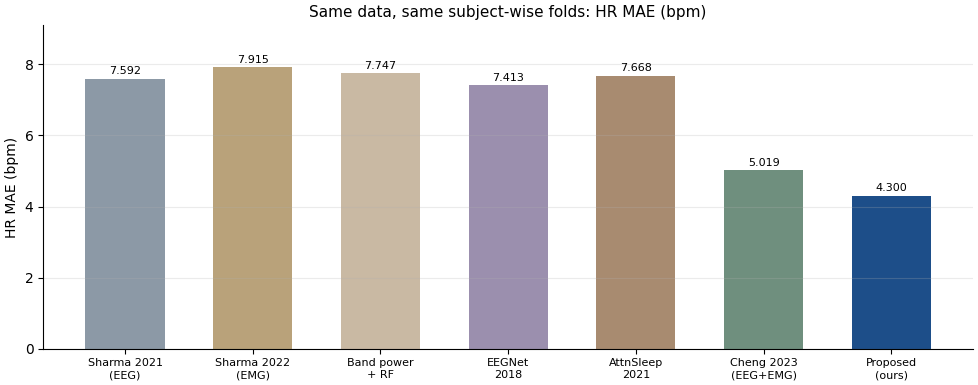

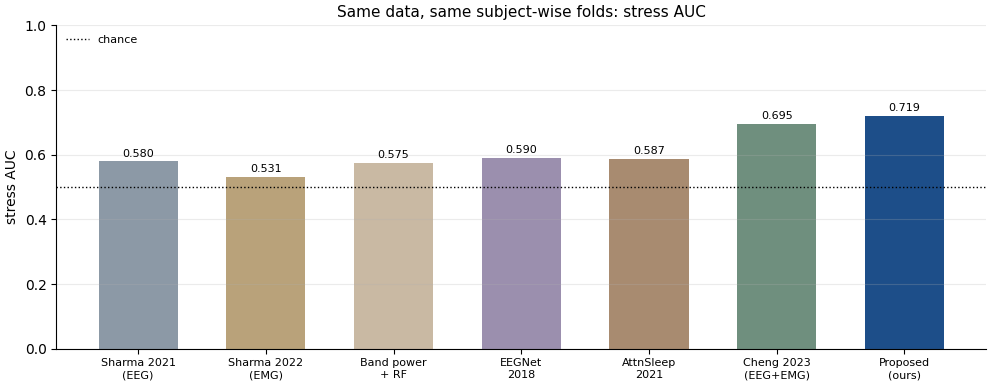

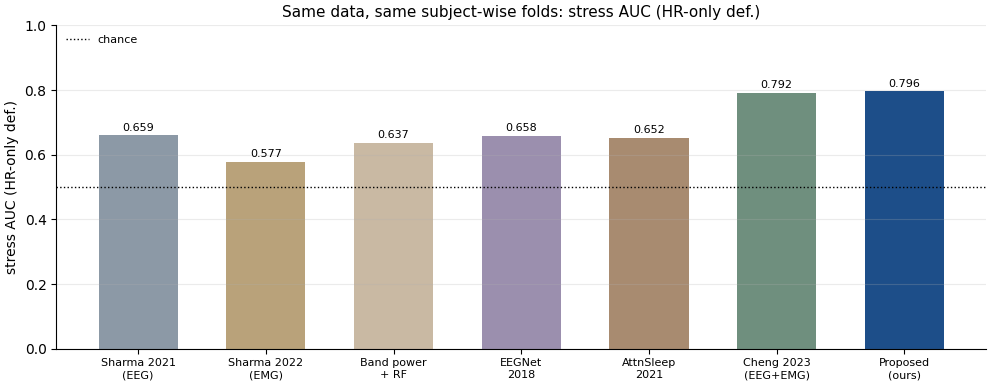

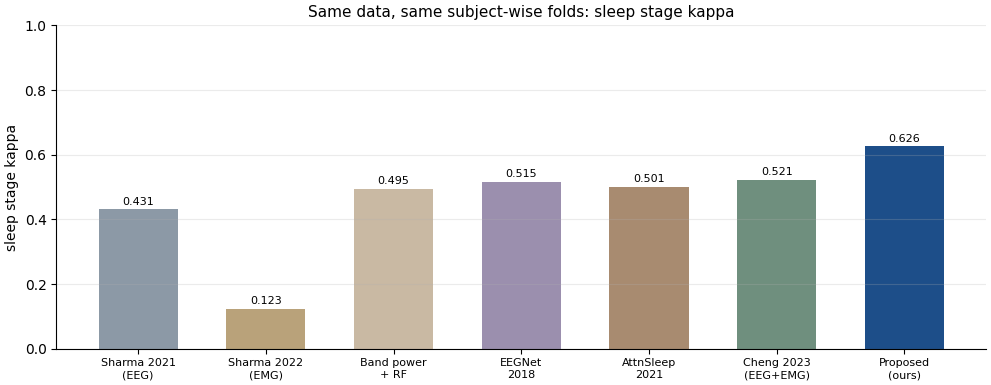

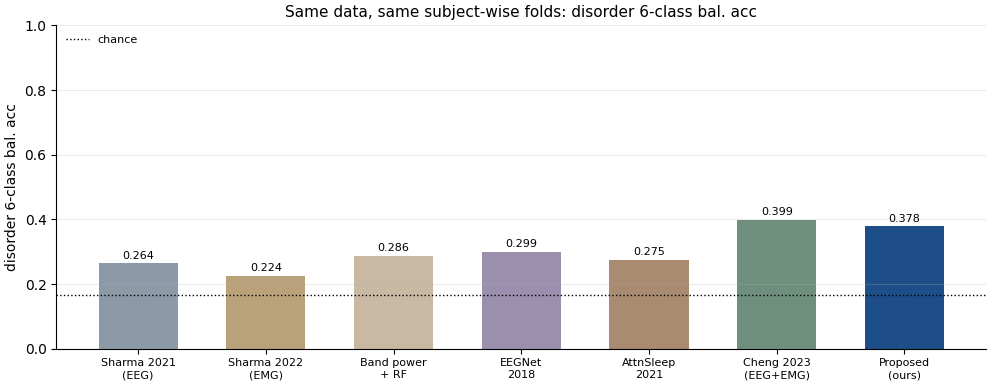

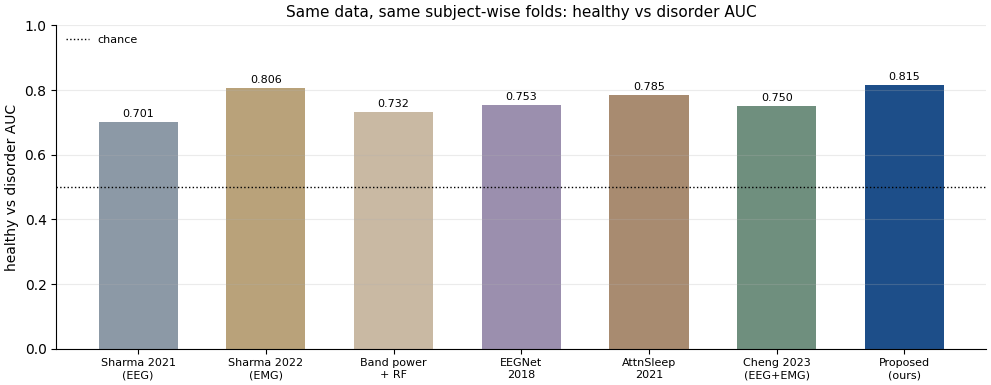

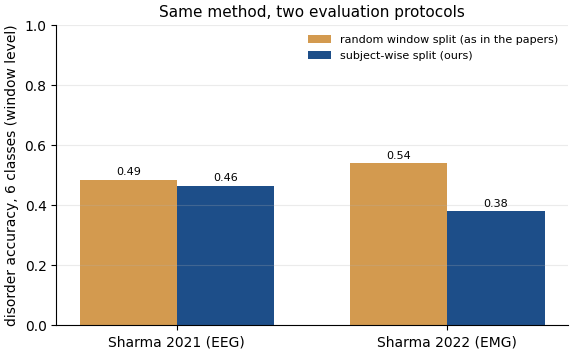

saved: tables/baselines/ (tableB01-B03, baselines_comparison.xlsx) and figures/{png,pdf,svg}/baselines/ (figB01-B07)


In [15]:
# Figures (separate files, PNG 600 dpi + PDF + SVG, same palette as the other thesis figures) and one Excel workbook
if COMPARE:
    for ext in ("png", "pdf", "svg"):
        for old in (ROOT / "figures" / ext / "baselines").glob(f"figB*.{ext}"): old.unlink()
    plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
                         "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "font.family": "DejaVu Sans", "font.size": 10,
                         "axes.titlesize": 11, "legend.fontsize": 8, "legend.frameon": False, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
    NAVY, SAND, SLATE, LIGHT = "#1d4e89", "#d39a4f", "#8c99a6", "#7fa3c9"
    def color(n): return PAL[n]
    def save(fig, name):
        for ext in ("png", "pdf", "svg"): fig.savefig(ROOT / "figures" / ext / "baselines" / f"{name}.{ext}")
        plt.show(); plt.close(fig)
    PLOTS = (("HR MAE (bpm)", "hr_mae", None), ("stress AUC", "stress_auc", 0.5), ("stress AUC (HR-only def.)", "stress_auc_hr_only", 0.5),
             ("sleep stage kappa", "sleep_stage_kappa", 0.0), ("disorder 6-class bal. acc", "disorder_bal_acc", 1 / 6),
             ("healthy vs disorder AUC", "healthy_vs_disorder_auc", 0.5))
    for i, (m, fname, chance) in enumerate(PLOTS, 1):
        names = list(cmp.index); v = cmp[m].astype(float).to_numpy()
        fig, ax = plt.subplots(figsize=(12, 4.2))
        b = ax.bar([SHORT[n] for n in names], v, color=[color(n) for n in names], width=.62); ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)
        if chance: ax.axhline(chance, color="k", ls=":", lw=1, label="chance"); ax.legend(loc="upper left")
        ax.set_ylim(0, max(v) * 1.15 if m.startswith("HR MAE") else 1.0)
        ax.set_ylabel(m); ax.set_title(f"Same data, same subject-wise folds: {m}"); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", labelsize=8)
        save(fig, f"figB{i:02d}_comparison_{fname}")
    lf = TABB / "tableB03_leakage_random_vs_subject_split.csv"
    leak = pd.read_csv(lf) if lf.exists() else None
    if leak is not None:
        meth = list(dict.fromkeys(leak.method)); x = np.arange(len(meth)); w = .36
        fig, ax = plt.subplots(figsize=(6.6, 3.9))
        for j, (prot, c, lab) in enumerate((("random", SAND, "random window split (as in the papers)"), ("subject", NAVY, "subject-wise split (ours)"))):
            v = [leak[(leak.method == mm) & leak.protocol.str.startswith(prot)]["window accuracy"].iloc[0] for mm in meth]
            b = ax.bar(x + (j - .5) * w, v, w, color=c, label=lab); ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
        ax.set_xticks(x); ax.set_xticklabels(["Sharma 2021 (EEG)" if "2021" in mm else "Sharma 2022 (EMG)" for mm in meth])
        ax.set_ylim(0, 1); ax.set_ylabel("disorder accuracy, 6 classes (window level)")
        ax.set_title("Same method, two evaluation protocols"); ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
        save(fig, "figB07_leakage_random_vs_subject_split")
    with pd.ExcelWriter(TABB / "baselines_comparison.xlsx") as w:
        cmp.to_excel(w, sheet_name="comparison"); tests.to_excel(w, sheet_name="paired_tests", index=False)
        if leak is not None: leak.to_excel(w, sheet_name="leakage", index=False)
    print("saved: tables/baselines/ (tableB01-B03, baselines_comparison.xlsx) and figures/{png,pdf,svg}/baselines/ (figB01-B07)")

In [16]:
# Extended visual comparison - shared helpers (per-subject confusion matrices, subject-level disorder decisions, palette)
if COMPARE:
    from sklearn.metrics import roc_curve, confusion_matrix, f1_score as f1s, recall_score
    from matplotlib.colors import LinearSegmentedColormap
    TEAL, ROSE = "#3f8f8a", "#b5546b"
    CMAP = LinearSegmentedColormap.from_list("thesis", ["#f4f7fa", "#9fb9d6", NAVY])
    ORDER = list(COMPARED)
    BASE = [n for n in ORDER if n != OURS]
    MAIN = BASE + [OURS]
    LABEL = {n: SHORT[n].replace("\n", " ") for n in MODELS}
    pc, sc = [f"p_{c}" for c in DIS], [f"p_{s}" for s in STG]

    def stage_pred(d): return d[sc].to_numpy().argmax(1)
    def subj_table(d):
        S = d.groupby("record").agg(dis=("dis", "first"), group=("group", "first"), fold=("fold", "first"), **{c: (c, "mean") for c in pc})
        S["pred"] = S[pc].to_numpy().argmax(1); return S
    SUBJ = {n: subj_table(D[n]) for n in ORDER}
    CM_STAGE = {}
    for n in ORDER:
        d = D[n]; y, p = d.stg.to_numpy(), stage_pred(d); recs = d.record.to_numpy()
        CM_STAGE[n] = {r: confusion_matrix(y[recs == r], p[recs == r], labels=range(len(STG))) for r in np.unique(recs)}
    def kappa_cm(cm):
        n = cm.sum(); po = np.trace(cm) / n; pe = (cm.sum(0) * cm.sum(1)).sum() / n ** 2
        return (po - pe) / (1 - pe)
    print("methods:", [LABEL[n] for n in ORDER])

methods: ['Sharma 2021 (EEG)', 'Sharma 2022 (EMG)', 'Band power + RF', 'EEGNet 2018', 'AttnSleep 2021', 'Cheng 2023 (EEG+EMG)', 'Proposed (ours)']


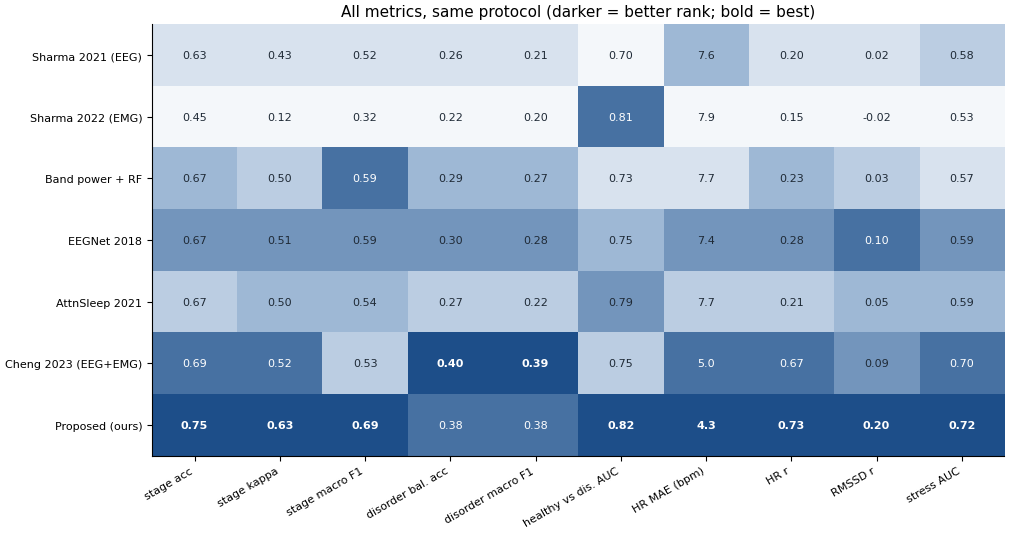

In [17]:
# Figure B08: heat map of every metric for every method (colour = rank within the metric, number = value)
if COMPARE:
    cols = ["sleep stage acc", "sleep stage kappa", "sleep stage macro F1", "disorder 6-class bal. acc", "disorder 6-class macro F1",
            "healthy vs disorder AUC", "HR MAE (bpm)", "HR r", "RMSSD r", "stress AUC"]
    T = cmp.loc[ORDER, cols].astype(float)
    R = T.rank(ascending=False); R["HR MAE (bpm)"] = T["HR MAE (bpm)"].rank(ascending=True)
    fig, ax = plt.subplots(figsize=(11, 5.6))
    ax.imshow(-R.to_numpy(), cmap=CMAP, aspect="auto"); ax.grid(False)
    for i in range(T.shape[0]):
        for j in range(T.shape[1]):
            ax.text(j, i, f"{T.iat[i, j]:.2f}" if j != 6 else f"{T.iat[i, j]:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if R.iat[i, j] <= 2 else "#1f2a36", fontweight="bold" if R.iat[i, j] == 1 else "normal")
    ax.set_xticks(range(len(cols)), [c.replace("disorder 6-class", "disorder").replace("sleep stage", "stage").replace("healthy vs disorder", "healthy vs dis.") for c in cols], rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(ORDER)), [LABEL[n] for n in ORDER], fontsize=8)
    ax.set_title("All metrics, same protocol (darker = better rank; bold = best)")
    save(fig, "figB08_heatmap_all_metrics")

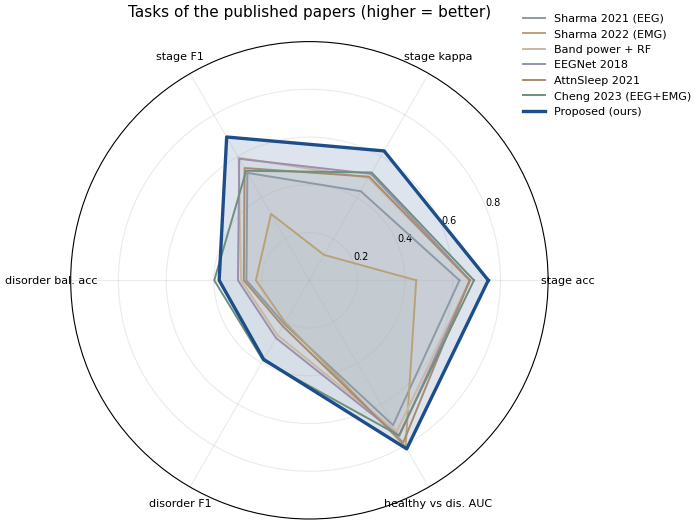

In [18]:
# Figure B09: radar chart of the published methods vs the proposed method on the tasks of the papers (sleep stage, disorder)
if COMPARE:
    axes_m = ["sleep stage acc", "sleep stage kappa", "sleep stage macro F1", "disorder 6-class bal. acc", "disorder 6-class macro F1", "healthy vs disorder AUC"]
    lab = ["stage acc", "stage kappa", "stage F1", "disorder bal. acc", "disorder F1", "healthy vs dis. AUC"]
    ang = np.linspace(0, 2 * np.pi, len(axes_m), endpoint=False).tolist(); ang += ang[:1]
    fig = plt.figure(figsize=(6.2, 6.2)); ax = fig.add_subplot(111, polar=True)
    for n in MAIN:
        v = cmp.loc[n, axes_m].astype(float).tolist(); v += v[:1]
        ax.plot(ang, v, color=PAL[n], lw=2.4 if n == OURS else 1.4, label=LABEL[n]); ax.fill(ang, v, color=PAL[n], alpha=.15 if n == OURS else .05)
    ax.set_xticks(ang[:-1], lab, fontsize=8); ax.set_ylim(0, 1); ax.set_yticks([.2, .4, .6, .8], ["0.2", "0.4", "0.6", "0.8"], fontsize=7)
    ax.set_title("Tasks of the published papers (higher = better)", pad=18); ax.legend(loc="upper right", bbox_to_anchor=(1.32, 1.08), fontsize=8)
    save(fig, "figB09_radar_paper_tasks")

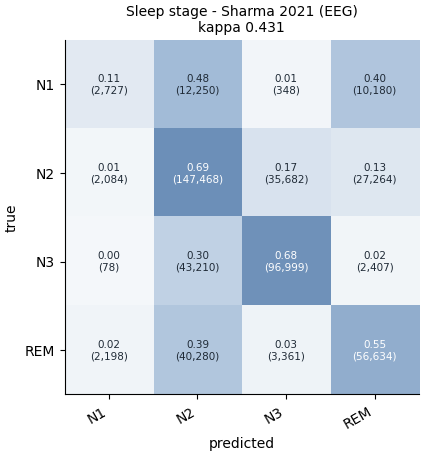

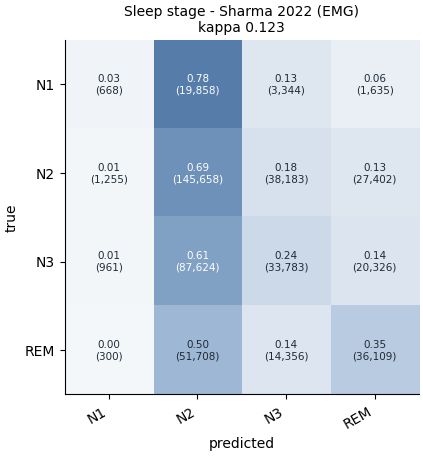

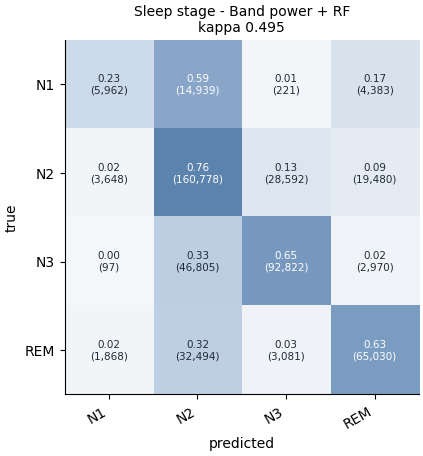

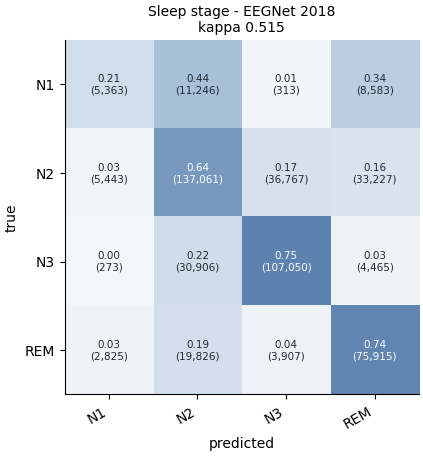

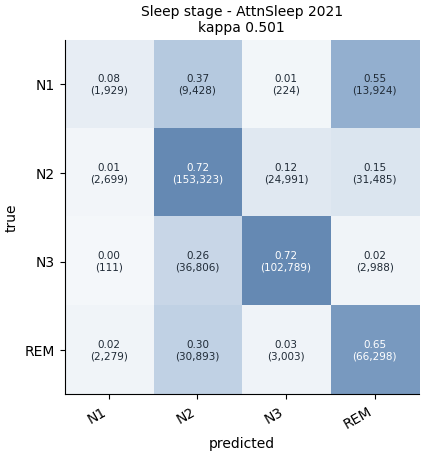

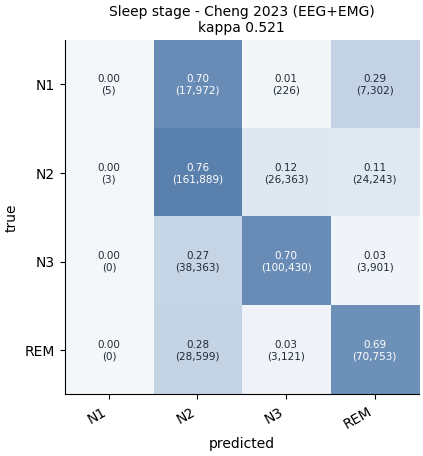

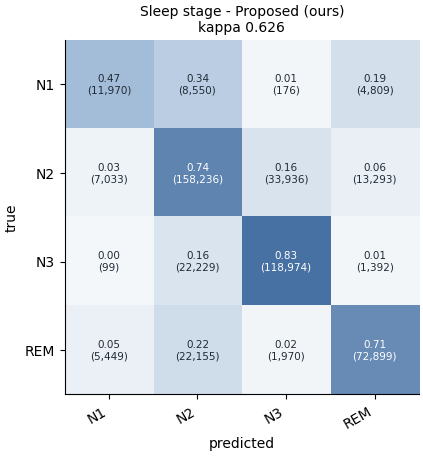

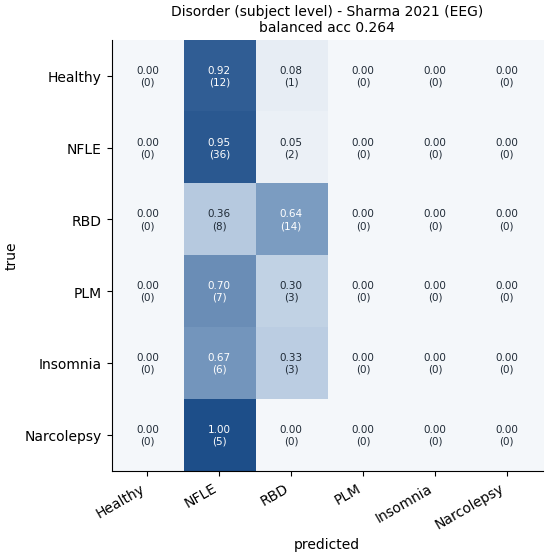

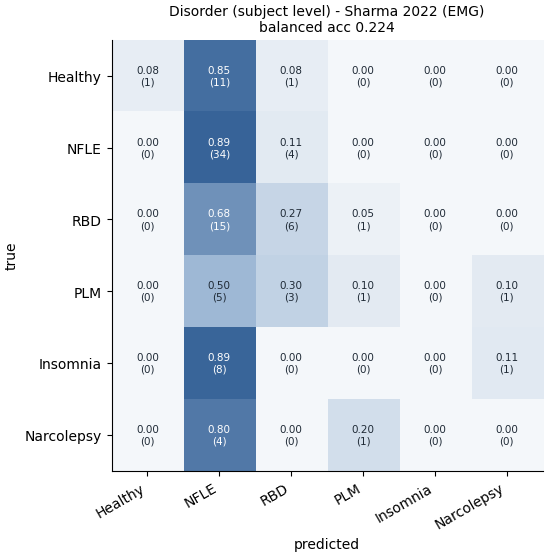

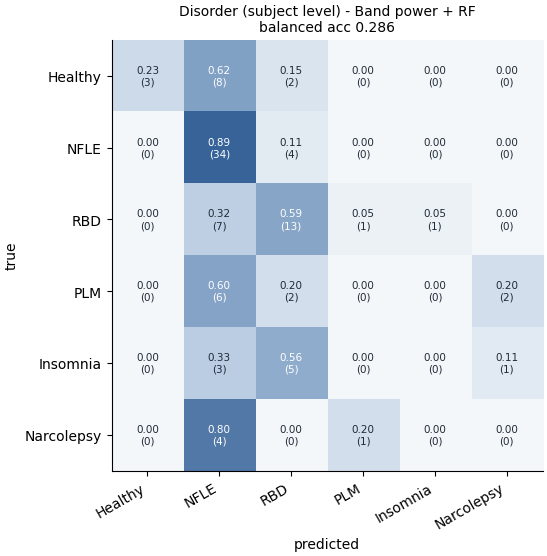

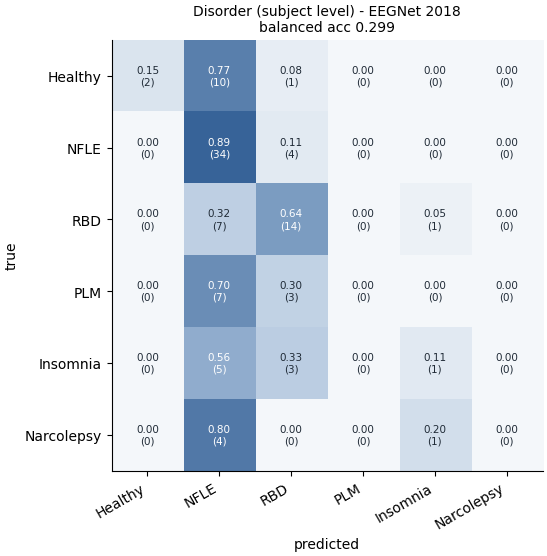

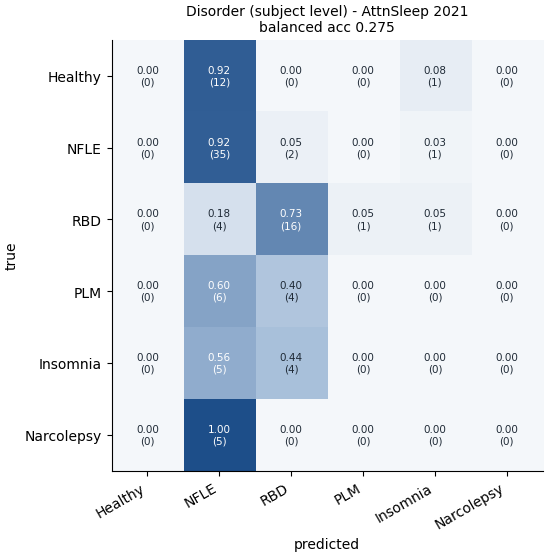

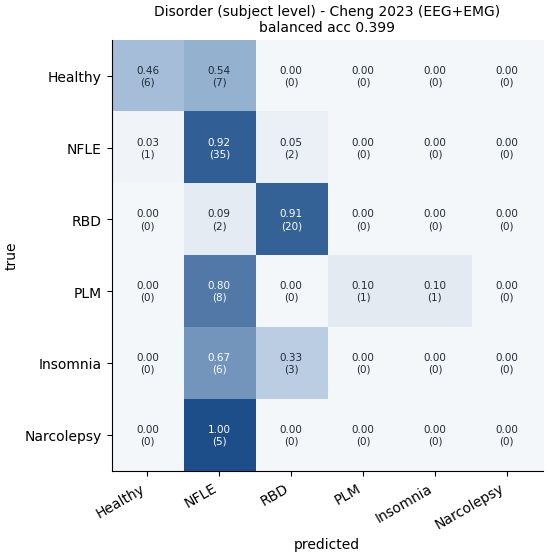

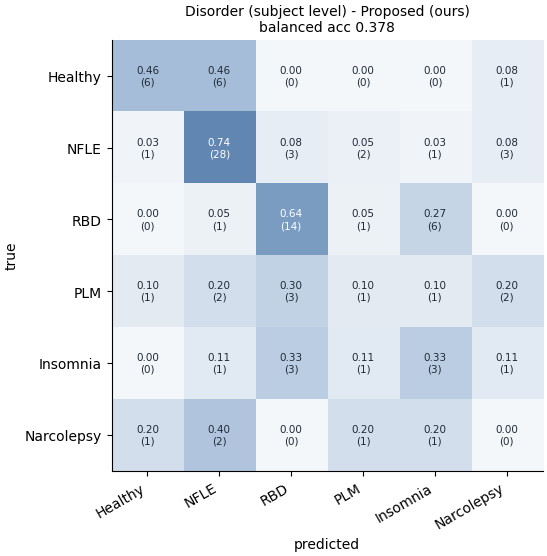

In [19]:
# Figures B10-B11: sleep-stage and disorder confusion matrices of every method (row-normalised, one file per method)
if COMPARE:
    def conf_plot(cm, labels, title, name):
        p = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        fig, ax = plt.subplots(figsize=(4.6 if len(labels) == 4 else 5.6,) * 2)
        ax.imshow(p, cmap=CMAP, vmin=0, vmax=1); ax.grid(False)
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{p[i, j]:.2f}\n({int(cm[i, j]):,})", ha="center", va="center", fontsize=7.5, color="white" if p[i, j] > .55 else "#1f2a36")
        ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right"); ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10); save(fig, name)
    TAG = {n: p_.name for n, p_ in MODELS.items()}
    for n in MAIN:
        conf_plot(sum(CM_STAGE[n].values()), STG, f"Sleep stage - {LABEL[n]}\nkappa {cmp.loc[n, 'sleep stage kappa']:.3f}", f"figB10_stage_confusion_{TAG[n]}")
    for n in MAIN:
        s = SUBJ[n]; s = s[s.dis != M.IGNORE]
        conf_plot(confusion_matrix(s.dis, s.pred, labels=range(len(DIS))), DIS,
                  f"Disorder (subject level) - {LABEL[n]}\nbalanced acc {cmp.loc[n, 'disorder 6-class bal. acc']:.3f}", f"figB11_disorder_confusion_{TAG[n]}")

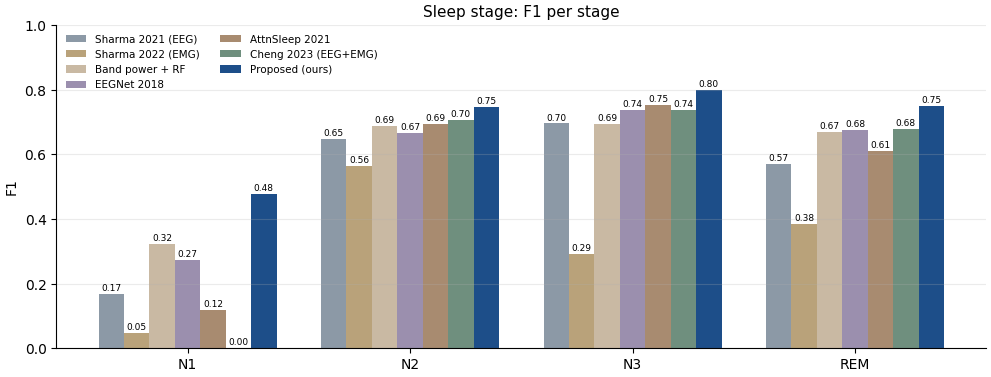

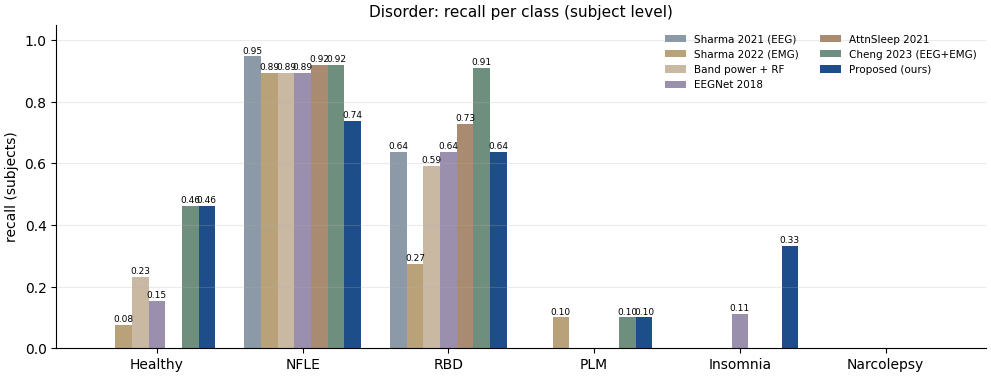

In [20]:
# Figures B12-B13: per-class results - F1 of every sleep stage and recall of every disorder class
if COMPARE:
    x = np.arange(len(STG)); w = .8 / len(MAIN)
    fig, ax = plt.subplots(figsize=(12, 4.2))
    for i, n in enumerate(MAIN):
        v = f1s(D[n].stg, stage_pred(D[n]), labels=range(len(STG)), average=None)
        b = ax.bar(x + (i - (len(MAIN) - 1) / 2) * w, v, w, color=PAL[n], label=LABEL[n]); ax.bar_label(b, labels=[f"{x:.2f}" if x > 0 else "" for x in v], fontsize=6.5, padding=1)
    ax.set_xticks(x, STG); ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.set_title("Sleep stage: F1 per stage"); ax.legend(ncol=2, fontsize=7.5, loc="upper left"); ax.grid(axis="x", visible=False)
    save(fig, "figB12_stage_f1_per_class")
    x = np.arange(len(DIS))
    fig, ax = plt.subplots(figsize=(12, 4.2))
    for i, n in enumerate(MAIN):
        s = SUBJ[n]; s = s[s.dis != M.IGNORE]
        v = recall_score(s.dis, s.pred, labels=range(len(DIS)), average=None, zero_division=0)
        b = ax.bar(x + (i - (len(MAIN) - 1) / 2) * w, v, w, color=PAL[n], label=LABEL[n]); ax.bar_label(b, labels=[f"{x:.2f}" if x > 0 else "" for x in v], fontsize=6.5, padding=1)
    ax.set_xticks(x, DIS); ax.set_ylim(0, 1.05); ax.set_ylabel("recall (subjects)"); ax.set_title("Disorder: recall per class (subject level)")
    ax.legend(ncol=2, fontsize=7.5, loc="upper right"); ax.grid(axis="x", visible=False)
    save(fig, "figB13_disorder_recall_per_class")

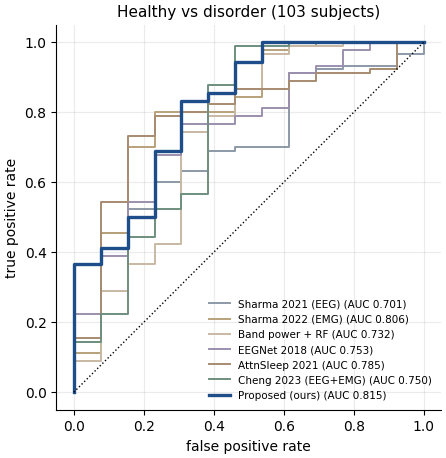

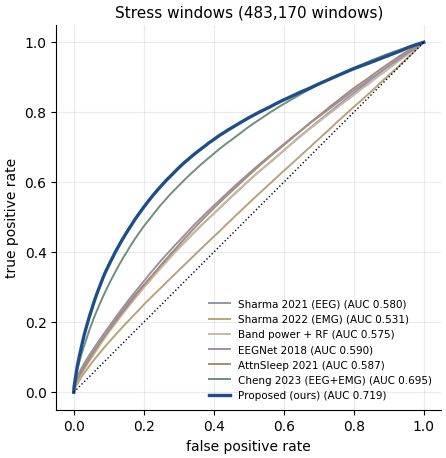

In [21]:
# Figures B14-B15: ROC curves - healthy vs disorder (subject level) and stress (window level)
if COMPARE:
    fig, ax = plt.subplots(figsize=(5.2, 5.0))
    for n in MAIN:
        s = SUBJ[n]; y = (s.group != "Healthy").astype(int); sc_ = 1 - s.p_Healthy
        fpr, tpr, _ = roc_curve(y, sc_); ax.plot(fpr, tpr, color=PAL[n], lw=2.4 if n == OURS else 1.4, label=f"{LABEL[n]} (AUC {roc_auc_score(y, sc_):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title("Healthy vs disorder (103 subjects)"); ax.legend(fontsize=7.5, loc="lower right"); ax.set_aspect("equal")
    save(fig, "figB14_roc_healthy_vs_disorder")
    fig, ax = plt.subplots(figsize=(5.2, 5.0))
    for n in MAIN:
        d = D[n]; y = ((zin(d, "hr") - zin(d, "rmssd")) > 1).astype(int); s_ = zin(d, "hr_pred") - zin(d, "rmssd_pred")
        fpr, tpr, _ = roc_curve(y, s_); k = np.linspace(0, len(fpr) - 1, 400).astype(int)
        ax.plot(fpr[k], tpr[k], color=PAL[n], lw=2.4 if n == OURS else 1.4, label=f"{LABEL[n]} (AUC {roc_auc_score(y, s_):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title("Stress windows (483,170 windows)"); ax.legend(fontsize=7.5, loc="lower right"); ax.set_aspect("equal")
    save(fig, "figB15_roc_stress")

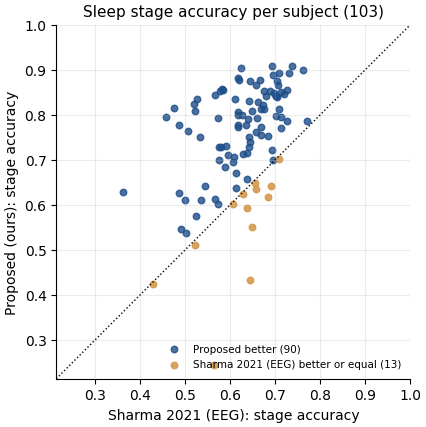

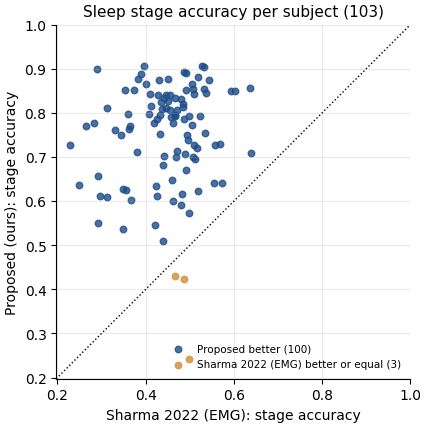

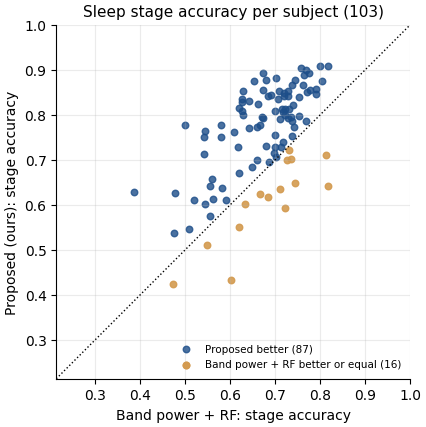

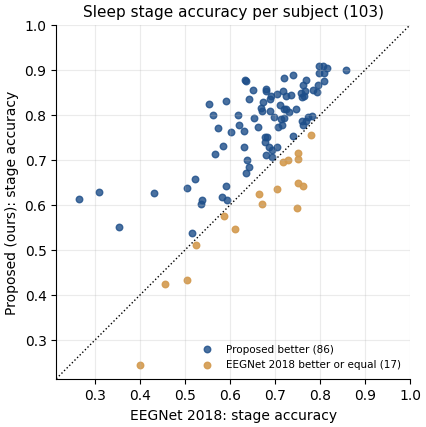

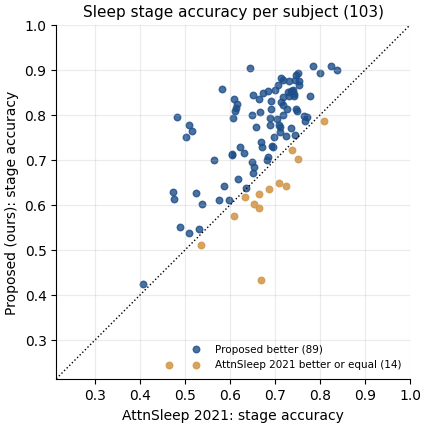

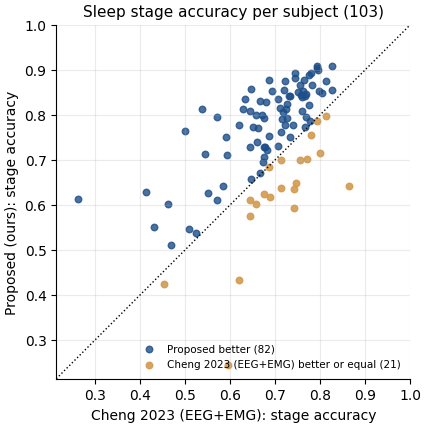

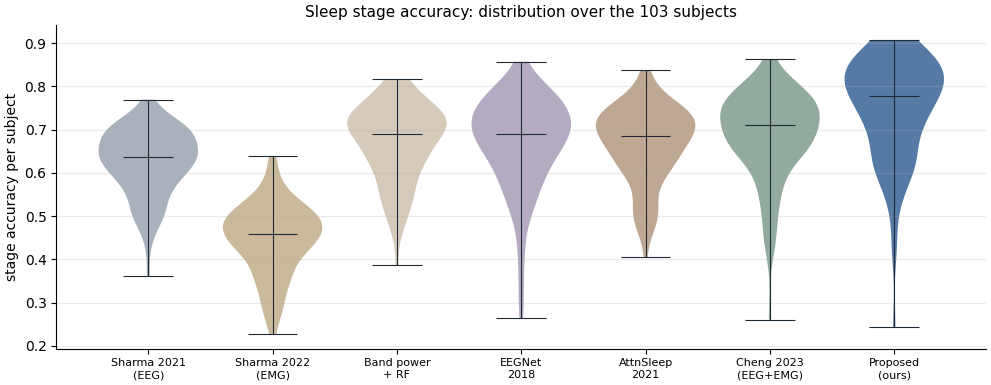

In [22]:
# Figures B16-B17: every subject - Proposed vs each published method (points above the diagonal = PMRT better) and distributions
if COMPARE:
    for n in BASE:
        a, b = PS[OURS]["stage acc"].align(PS[n]["stage acc"], join="inner")
        fig, ax = plt.subplots(figsize=(4.6, 4.6))
        better = a > b
        ax.scatter(b[better], a[better], s=22, color=NAVY, alpha=.8, label=f"Proposed better ({better.sum()})")
        ax.scatter(b[~better], a[~better], s=22, color=SAND, alpha=.9, label=f"{LABEL[n]} better or equal ({(~better).sum()})")
        lo = min(a.min(), b.min()) - .03; ax.plot([lo, 1], [lo, 1], "k:", lw=1); ax.set_xlim(lo, 1); ax.set_ylim(lo, 1); ax.set_aspect("equal")
        ax.set_xlabel(f"{LABEL[n]}: stage accuracy"); ax.set_ylabel("Proposed (ours): stage accuracy"); ax.legend(fontsize=7.5, loc="lower right")
        ax.set_title("Sleep stage accuracy per subject (103)"); save(fig, f"figB16_subject_scatter_stage_{TAG[n]}")
    fig, ax = plt.subplots(figsize=(12, 4.2))
    data = [PS[n]["stage acc"].dropna().to_numpy() for n in ORDER]
    vp = ax.violinplot(data, showmedians=True, widths=.8)
    for body, n in zip(vp["bodies"], ORDER): body.set_facecolor(PAL[n]); body.set_alpha(.75); body.set_edgecolor("none")
    for k_ in ("cmedians", "cbars", "cmins", "cmaxes"): vp[k_].set_color("#1f2a36"); vp[k_].set_linewidth(.8)
    ax.set_xticks(range(1, len(ORDER) + 1), [SHORT[n] for n in ORDER], fontsize=8); ax.set_ylabel("stage accuracy per subject")
    ax.set_title("Sleep stage accuracy: distribution over the 103 subjects"); ax.grid(axis="x", visible=False)
    save(fig, "figB17_subject_distribution_stage_acc")

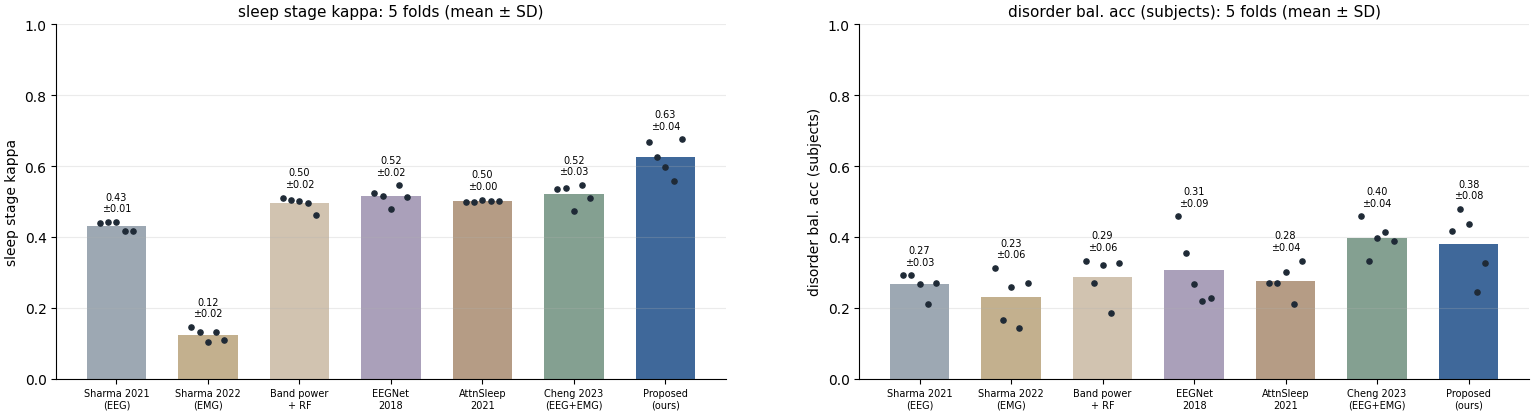

In [23]:
# Figure B18: per-fold results (each dot = one fold, bar = mean) - stability of every method
if COMPARE:
    fig, axs = plt.subplots(1, 2, figsize=(19, 4.6))
    for ax, (lab_, fn) in zip(axs, (("sleep stage kappa", lambda d: cohen_kappa_score(d.stg, stage_pred(d))),
                                     ("disorder bal. acc (subjects)", None))):
        for i, n in enumerate(ORDER):
            if fn is not None: v = [fn(g) for _, g in D[n].groupby("fold")]
            else:
                s = SUBJ[n]; s = s[s.dis != M.IGNORE]; v = [balanced_accuracy_score(g.dis, g.pred) for _, g in s.groupby("fold")]
            ax.bar(i, np.mean(v), .65, color=PAL[n], alpha=.85); ax.scatter(np.full(len(v), i) + np.linspace(-.18, .18, len(v)), v, s=14, color="#1f2a36", zorder=3)
            ax.text(i, max(v) + .03, f"{np.mean(v):.2f}\n±{np.std(v):.2f}", ha="center", fontsize=7)
        ax.set_xticks(range(len(ORDER)), [SHORT[n] for n in ORDER], fontsize=7); ax.set_ylim(0, 1); ax.set_ylabel(lab_); ax.grid(axis="x", visible=False)
        ax.set_title(f"{lab_}: 5 folds (mean ± SD)")
    save(fig, "figB18_per_fold_stability")

                                                                                   low  median   high
Sharma et al. 2021 (EEG, sub-bands + Hjorth, boosted trees) stage kappa          0.402   0.432  0.455
                                                            stage acc            0.611   0.629  0.644
                                                            disorder bal. acc    0.226   0.264  0.300
                                                            healthy vs dis. AUC  0.543   0.703  0.842
Sharma et al. 2022 (EMG, wavelet + Hjorth, bagged trees)    stage kappa          0.103   0.123  0.143
                                                            stage acc            0.432   0.448  0.463
                                                            disorder bal. acc    0.174   0.223  0.285
                                                            healthy vs dis. AUC  0.634   0.810  0.940
Band power + Random Forest (EEG + EMG, classic baseline)    stage kappa          0

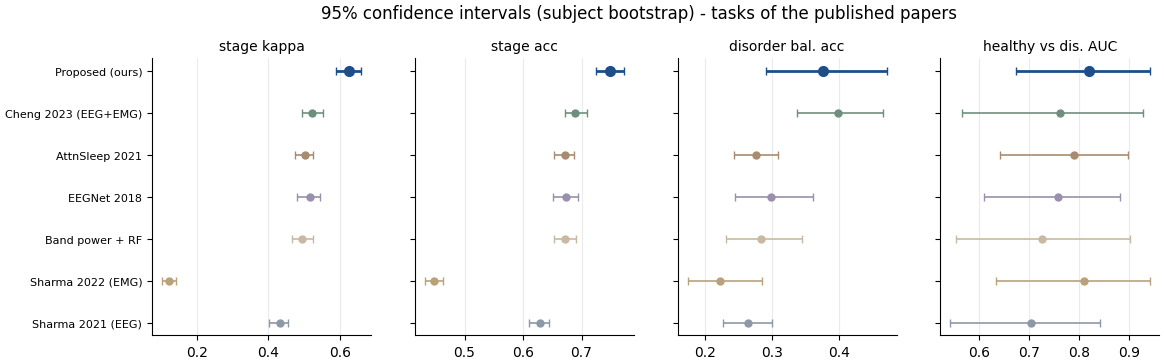

In [24]:
# Figure B19: 95% confidence intervals (subject bootstrap, 1000 resamples) for the tasks of the papers
if COMPARE:
    rng = np.random.default_rng(42); B = 1000
    def boot(n):
        recs = np.array(sorted(CM_STAGE[n])); S = SUBJ[n].loc[recs]; cms = np.stack([CM_STAGE[n][r] for r in recs])
        out = {"stage kappa": [], "stage acc": [], "disorder bal. acc": [], "healthy vs dis. AUC": []}
        for _ in range(B):
            i = rng.integers(0, len(recs), len(recs)); cm = cms[i].sum(0); s = S.iloc[i]; s6 = s[s.dis != M.IGNORE]
            out["stage kappa"].append(kappa_cm(cm)); out["stage acc"].append(np.trace(cm) / cm.sum())
            out["disorder bal. acc"].append(balanced_accuracy_score(s6.dis, s6.pred))
            yb = (s.group != "Healthy").astype(int)
            out["healthy vs dis. AUC"].append(roc_auc_score(yb, 1 - s.p_Healthy) if yb.nunique() > 1 else np.nan)
        return {k: np.nanpercentile(v, [2.5, 50, 97.5]) for k, v in out.items()}
    CI = {n: boot(n) for n in MAIN}
    ci_tab = pd.DataFrame({(n, k): {"low": v[0], "median": v[1], "high": v[2]} for n, d in CI.items() for k, v in d.items()}).T
    ci_tab.to_csv(TABB / "tableB04_bootstrap_ci_paper_tasks.csv"); print(ci_tab.round(3).to_string())
    mets = list(CI[OURS]); fig, axs = plt.subplots(1, len(mets), figsize=(13, 3.6), sharey=True)
    for ax, m in zip(axs, mets):
        for i, n in enumerate(MAIN):
            lo, md, hi = CI[n][m]; ax.errorbar(md, i, xerr=[[md - lo], [hi - md]], fmt="o", color=PAL[n], ms=7 if n == OURS else 5, capsize=3, lw=2 if n == OURS else 1.2)
        ax.set_title(m, fontsize=10); ax.grid(axis="y", visible=False)
    axs[0].set_yticks(range(len(MAIN)), [LABEL[n] for n in MAIN], fontsize=8)
    fig.suptitle("95% confidence intervals (subject bootstrap) - tasks of the published papers", y=1.03)
    save(fig, "figB19_bootstrap_ci_paper_tasks")

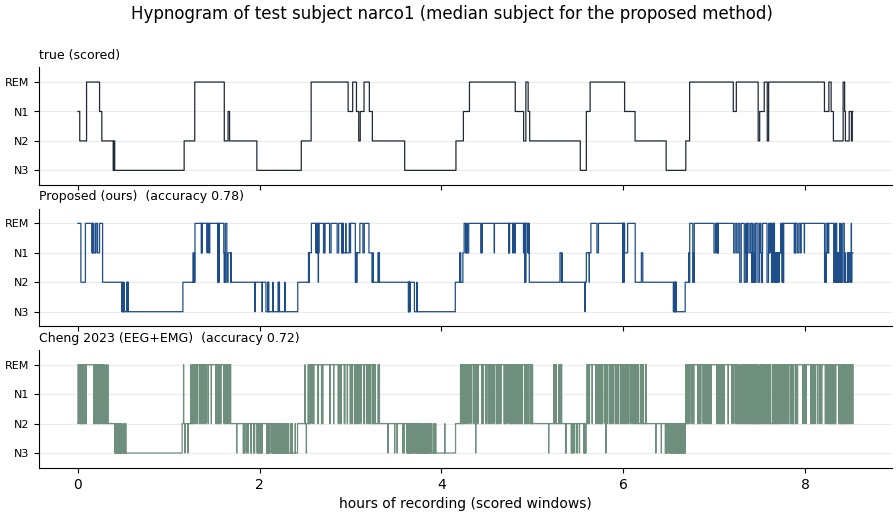

In [25]:
# Figure B20: hypnogram of one test subject (median accuracy of the proposed method) - true stages vs Proposed vs the best published method
if COMPARE:
    med = PS[OURS]["stage acc"].sort_values(); rec = med.index[len(med) // 2]
    best_base = max(BASE, key=lambda n: cmp.loc[n, "sleep stage kappa"])
    show = [("true (scored)", None), (LABEL[OURS], OURS), (LABEL[best_base], best_base)]
    fig, axs = plt.subplots(len(show), 1, figsize=(11, 5.2), sharex=True)
    for ax, (lab_, n) in zip(axs, show):
        d = D[OURS if n is None else n]; g = d[d.record == rec]
        y = g.stg.to_numpy() if n is None else stage_pred(g); hrs = np.arange(len(g)) * 5 / 3600
        lvl = np.array([2, 1, 0, 3])[y]
        ax.step(hrs, lvl, where="post", color="#1f2a36" if n is None else PAL[n], lw=.9)
        ax.set_yticks(range(4), ["N3", "N2", "N1", "REM"], fontsize=8); ax.set_ylim(-.5, 3.5); ax.grid(axis="x", visible=False)
        acc = "" if n is None else f"  (accuracy {np.mean(y == g.stg.to_numpy()):.2f})"
        ax.set_title(f"{lab_}{acc}", fontsize=9, loc="left")
    axs[-1].set_xlabel("hours of recording (scored windows)")
    fig.suptitle(f"Hypnogram of test subject {rec} (median subject for the proposed method)", y=1.0)
    save(fig, "figB20_hypnogram_example")

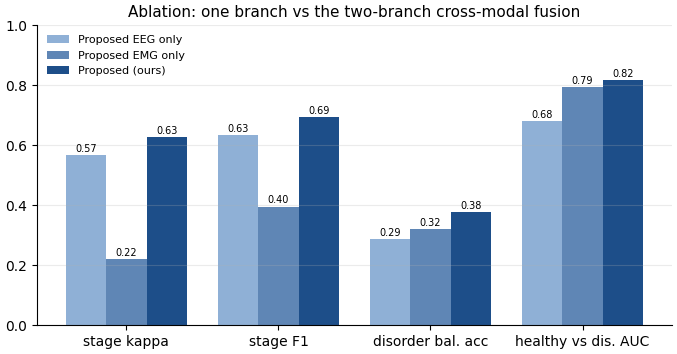

saved: figB08-B21


In [26]:
# Figure B21: value of the dual-branch fusion (Fig. 2 of the reference paper) - EEG only vs EMG only vs fusion
if COMPARE:
    abl = ABLATION
    mets = [("sleep stage kappa", "stage kappa"), ("sleep stage macro F1", "stage F1"), ("disorder 6-class bal. acc", "disorder bal. acc"), ("healthy vs disorder AUC", "healthy vs dis. AUC")]
    x = np.arange(len(mets)); w = .8 / len(abl)
    fig, ax = plt.subplots(figsize=(8.2, 3.9))
    for i, n in enumerate(abl):
        v = [CMP_ALL.loc[n, m] for m, _ in mets]
        b = ax.bar(x + (i - (len(abl) - 1) / 2) * w, v, w, color=PAL[n], label=LABEL[n]); ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
    ax.set_xticks(x, [l for _, l in mets]); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc="upper left"); ax.grid(axis="x", visible=False)
    ax.set_title("Ablation: one branch vs the two-branch cross-modal fusion")
    save(fig, "figB21_ablation_fusion")
    print("saved: figB08-B21")

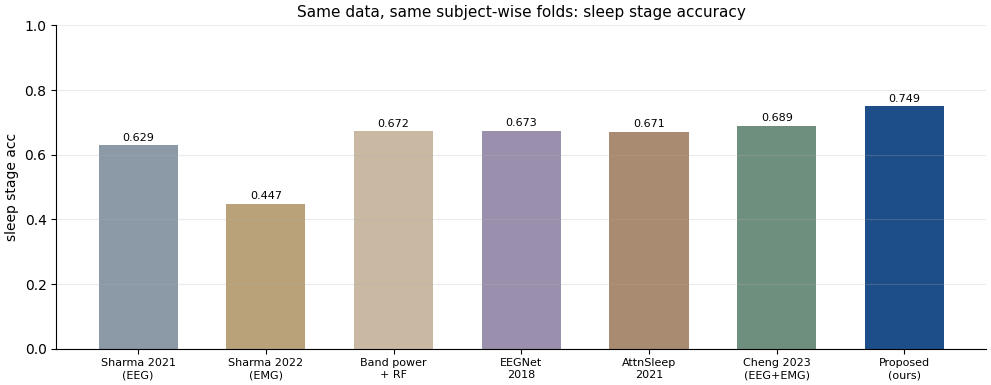

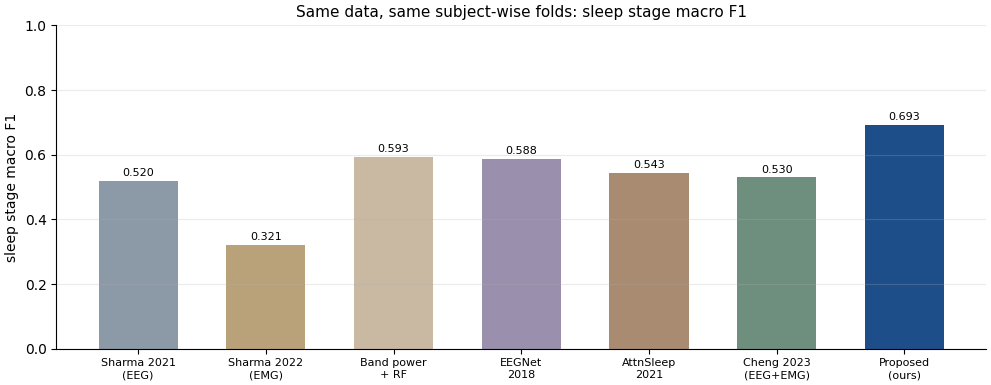

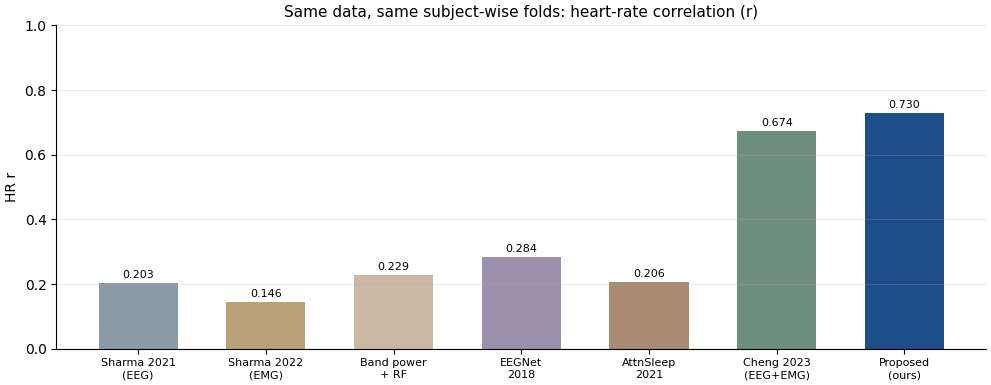

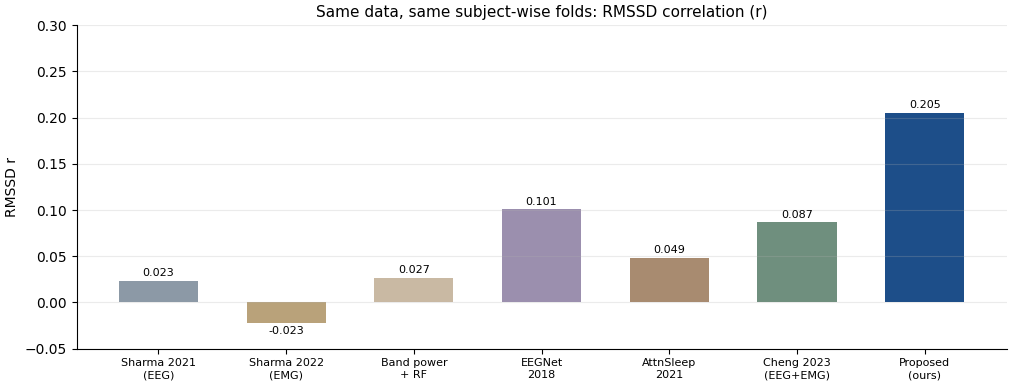

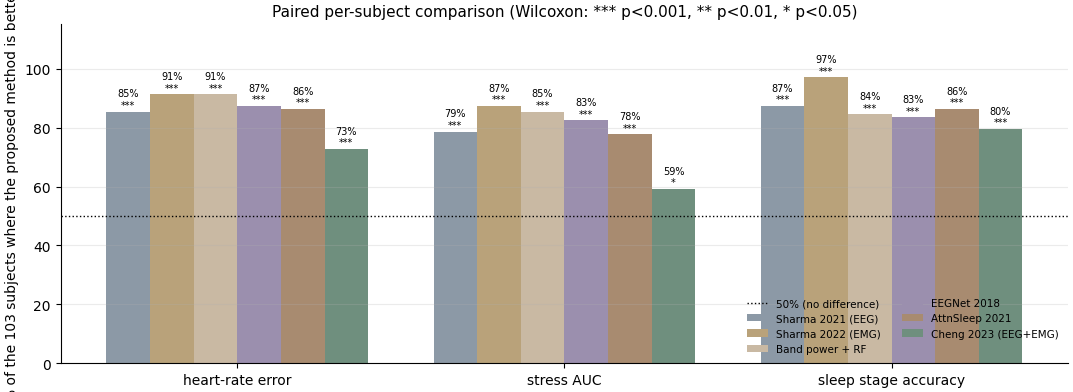

                   metric  Proposed (ours)  best published best published method  Proposed better  difference
          sleep stage acc            0.749           0.689  Cheng 2023 (EEG+EMG)             True       0.060
        sleep stage kappa            0.626           0.521  Cheng 2023 (EEG+EMG)             True       0.104
     sleep stage macro F1            0.693           0.593       Band power + RF             True       0.100
  healthy vs disorder AUC            0.815           0.806     Sharma 2022 (EMG)             True       0.009
             HR MAE (bpm)            4.300           5.019  Cheng 2023 (EEG+EMG)             True       0.719
                     HR r            0.730           0.674  Cheng 2023 (EEG+EMG)             True       0.056
                  RMSSD r            0.205           0.101           EEGNet 2018             True       0.104
               stress AUC            0.719           0.695  Cheng 2023 (EEG+EMG)             True       0.024
disorder 6

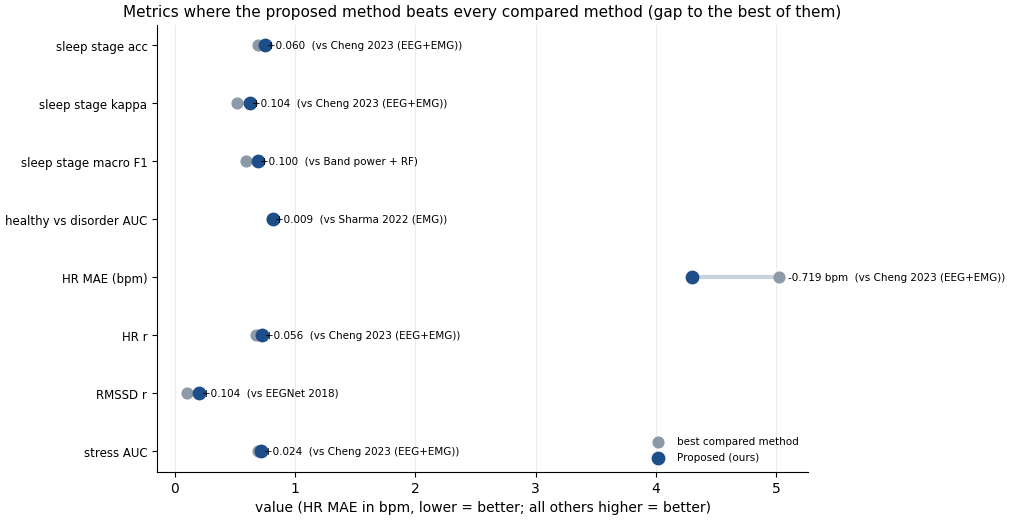


not better than the best published method (reported in tableB01 / figB05 / figB08): ['disorder 6-class bal. acc', 'disorder 6-class macro F1']
saved: figures/{png,pdf,svg}/baselines/figB08-B27, tables/baselines/tableB04-B05


In [27]:
# Figures B22-B27: the metrics where the proposed method is better than every compared method (each as a separate figure)
if COMPARE:
    def bar_metric(m, fname, title, ylim=(0, 1), fmt="%.3f"):
        v = cmp.loc[ORDER, m].astype(float).to_numpy()
        fig, ax = plt.subplots(figsize=(12, 4.2))
        b = ax.bar([SHORT[n] for n in ORDER], v, color=[PAL[n] for n in ORDER], width=.62); ax.bar_label(b, fmt=fmt, fontsize=8, padding=2)
        ax.set_ylim(*ylim); ax.set_ylabel(m); ax.set_title(title); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", labelsize=8)
        save(fig, fname)
    bar_metric("sleep stage acc", "figB22_comparison_sleep_stage_accuracy", "Same data, same subject-wise folds: sleep stage accuracy")
    bar_metric("sleep stage macro F1", "figB23_comparison_sleep_stage_macro_f1", "Same data, same subject-wise folds: sleep stage macro F1")
    bar_metric("HR r", "figB24_comparison_hr_correlation", "Same data, same subject-wise folds: heart-rate correlation (r)")
    bar_metric("RMSSD r", "figB25_comparison_rmssd_correlation", "Same data, same subject-wise folds: RMSSD correlation (r)", ylim=(-.05, .3))

    metrics = [("HR MAE", "heart-rate error"), ("stress AUC", "stress AUC"), ("stage acc", "sleep stage accuracy")]
    x = np.arange(len(metrics)); w = .8 / len(BASE)
    fig, ax = plt.subplots(figsize=(13, 4.4))
    for i, n in enumerate(BASE):
        rows_ = tests[tests["Proposed vs"] == n].set_index("per-subject metric")
        v = [100 * rows_.loc[m, "Proposed better in"] / rows_.loc[m, "subjects"] for m, _ in metrics]
        p = [rows_.loc[m, "Wilcoxon p"] for m, _ in metrics]
        b = ax.bar(x + (i - (len(BASE) - 1) / 2) * w, v, w, color=PAL[n], label=LABEL[n])
        ax.bar_label(b, labels=[f"{vv:.0f}%\n{'***' if pp < .001 else '**' if pp < .01 else '*' if pp < .05 else 'n.s.'}" for vv, pp in zip(v, p)], fontsize=7, padding=1)
    ax.axhline(50, color="k", ls=":", lw=1, label="50% (no difference)")
    ax.set_xticks(x, [l for _, l in metrics]); ax.set_ylim(0, 115); ax.set_ylabel("% of the 103 subjects where the proposed method is better")
    ax.set_title("Paired per-subject comparison (Wilcoxon: *** p<0.001, ** p<0.01, * p<0.05)"); ax.legend(fontsize=7.5, loc="lower right", ncol=2); ax.grid(axis="x", visible=False)
    save(fig, "figB26_paired_tests_subjects_better")

    lower_better = {"HR MAE (bpm)"}
    cand = ["sleep stage acc", "sleep stage kappa", "sleep stage macro F1", "healthy vs disorder AUC", "HR MAE (bpm)", "HR r", "RMSSD r", "stress AUC",
            "disorder 6-class bal. acc", "disorder 6-class macro F1"]
    rows_ = []
    for m in cand:
        ours = float(cmp.loc[OURS, m]); others = cmp.loc[BASE, m].astype(float)
        best_n = others.idxmin() if m in lower_better else others.idxmax(); best = float(others[best_n])
        gain = (best - ours) if m in lower_better else (ours - best)
        rows_.append({"metric": m, "Proposed (ours)": ours, "best published": best, "best published method": LABEL[best_n], "Proposed better": gain > 0, "difference": gain})
    win = pd.DataFrame(rows_); win.to_csv(TABB / "tableB05_pmrt_vs_best_published_method.csv", index=False)
    print(win.round(3).to_string(index=False))
    w_ = win[win["Proposed better"]].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8.4, 0.55 * len(w_) + 1.4))
    for i, r in w_.iterrows():
        ax.plot([r["best published"], r["Proposed (ours)"]], [i, i], color="#c9d3de", lw=3, zorder=1)
        ax.scatter(r["best published"], i, s=60, color=SLATE, zorder=2, label="best compared method" if i == 0 else None)
        ax.scatter(r["Proposed (ours)"], i, s=80, color=NAVY, zorder=3, label="Proposed (ours)" if i == 0 else None)
        unit = " bpm" if r.metric in lower_better else ""
        ax.text(max(r["Proposed (ours)"], r["best published"]) + .02 * (1 if r.metric not in lower_better else 4), i,
                f"{'-' if r.metric in lower_better else '+'}{abs(r.difference):.3f}{unit}  (vs {r['best published method']})", va="center", fontsize=7.5)
    ax.set_yticks(range(len(w_)), w_.metric, fontsize=8.5); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_title("Metrics where the proposed method beats every compared method (gap to the best of them)")
    ax.legend(fontsize=7.5, loc="lower right"); ax.set_xlabel("value (HR MAE in bpm, lower = better; all others higher = better)")
    save(fig, "figB27_pmrt_vs_best_published")
    not_better = win.loc[~win["Proposed better"], "metric"].tolist()
    if not_better: print("\nnot better than the best published method (reported in tableB01 / figB05 / figB08):", not_better)
    if not KAGGLE: drive.flush_and_unmount()
    print("saved: figures/{png,pdf,svg}/baselines/figB08-B27, tables/baselines/tableB04-B05")